# Sidewalk vs asphalt from IMU vibration: full dataset (11 recordings)

Camera frames give the surface labels (CLIP + hand labels), the 1D-CNN classifies the surface from acceleration only.

GPS speed and position are added to every window only to check the results (GPS check, GPS comparison, map).
The final model does not use GPS.

Extraction, CLIP, hand labels, frame labels and IMU windows were run with all 11 recordings (26 and 28 Oct included).
The two GPS cells and everything after the windows still show the earlier run on 9 recordings.

In [1]:
# 1. Setup: libraries and Google Drive (GPU runtime recommended for CLIP and the CNN)

!pip install -q rosbags

import zipfile
import shutil
import math
import os
import re
import sqlite3
import subprocess
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, welch
from scipy.constants import knot
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import ipywidgets as widgets
from IPython.display import display
import folium
from rosbags.highlevel import AnyReader
from rosbags.typesys import Stores, get_typestore
from transformers import CLIPModel, CLIPProcessor
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, classification_report
from google.colab import drive
warnings.filterwarnings("ignore", category = UserWarning)
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
# 2. Paths, the 11 recordings and helpers to find a zip and read GPS

drive_dir = Path("/content/drive/MyDrive")
data_dir = drive_dir / "scooter_data"
old_dir = data_dir / "classification"
out_dir = data_dir / "classification_full"
frames_root = old_dir / "frames_all"
bag_root = Path("/content/bags")
zip_dirs = [drive_dir, drive_dir / "Data"]
phone_gps_dir = drive_dir / "gps_datasets"
out_dir.mkdir(parents = True, exist_ok = True)
typestore = get_typestore(Stores.ROS2_HUMBLE)
device = "cuda" if torch.cuda.is_available() else "cpu"
classes = ["sidewalk", "asphalt"]

recs = {
    "scooter_15min": "scooter_15min_20261008_170556_all_rgb_imu",
    "lab_to_home": "lab_to_home_15min_20261012_184113",
    "gps_outdoor": "gps_outdoor_10min_20261012_172325_gps",
    "field_recording": "field_recording_20261013_171548",
    "field_1014": "field_recording_20261014_165104",
    "field_1016": "field_recording_nogps_20261016_170845",
    "field_1019": "field_recording_nogps_20261019_165722",
    "field_1020": "field_recording_nogps_20261020_170307",
    "field_1021": "field_recording_20261021_171639",
    "field_1026": "field_recording_nogps_20261026_170512",
    "field_1028": "no_gps_color_imu_10min_20261028_170755",
}

phone_gps = {
    "field_1016": "University_of_Virginia-2026-10-16_21-09-51.zip",
    "field_1019": "University_of_Virginia-2026-10-19_20-56-30.zip",
    "field_1020": "University_of_Virginia-2026-10-20_21-03-08.zip",
    "field_1021": "University_of_Virginia-2026-10-21_21-13-17.zip",
}
phone_offset_s = {rec: 0.0 for rec in phone_gps}

def find_zip(folder):
    for d in zip_dirs:
        if (d / f"{folder}.zip").exists():
            return d / f"{folder}.zip"
    raise FileNotFoundError(f"{folder}.zip not found in {zip_dirs}; add a shortcut to My Drive")

def load_gps(folder, t0):
    path, source = data_dir / folder / "gps_parsed.csv", "scooter"
    if not path.exists():
        path, source = data_dir / folder / "gps_phone.csv", "phone"
    if not path.exists():
        return None
    gps = pd.read_csv(path)
    gps["time_sec"] = (gps["system_time_ns"] - t0) / 1e9
    gps["speed_mps"] = gps["speed_knots"] * knot
    gps["source"] = source
    return gps

print("device:", device)
for name, folder in recs.items():
    print(f"{name:16s} {folder}")

device: cuda
scooter_15min    scooter_15min_20261008_170556_all_rgb_imu
lab_to_home      lab_to_home_15min_20261012_184113
gps_outdoor      gps_outdoor_10min_20261012_172325_gps
field_recording  field_recording_20261013_171548
field_1014       field_recording_20261014_165104
field_1016       field_recording_nogps_20261016_170845
field_1019       field_recording_nogps_20261019_165722
field_1020       field_recording_nogps_20261020_170307
field_1021       field_recording_20261021_171639
field_1026       field_recording_nogps_20261026_170512
field_1028       no_gps_color_imu_10min_20261028_170755


In [3]:
# 3. Extract each recording once from its ROS bag: accel, gyro, GPS and one camera frame every 2 s (damaged bags are recovered)

import hashlib

def sqlite_cli():
    def has_dbpage(exe):
        r = subprocess.run([exe, ":memory:", "SELECT count(*) FROM sqlite_dbpage"], capture_output = True, text = True)
        return r.returncode == 0 and "no such table" not in r.stderr
    sys_exe = shutil.which("sqlite3")
    if sys_exe and has_dbpage(sys_exe):
        return sys_exe
    tool_dir = Path("/content/sqlite_tools")
    exe = tool_dir / "sqlite3"
    if exe.exists() and has_dbpage(str(exe)):
        return str(exe)
    name = "sqlite-tools-linux-x64-3540100.zip"
    sha3 = "555635de98534d87a67ee2e6e1b0d79f494b1b33b223477d3e7a8ea0c66e416f"
    zip_path = Path("/content") / name
    for year in (2026, 2025):
        r = subprocess.run(["wget", "-q", "-O", str(zip_path), f"https://www.sqlite.org/{year}/{name}"])
        if r.returncode == 0 and zip_path.stat().st_size > 0:
            break
    else:
        raise RuntimeError(f"could not download {name}; get it from https://www.sqlite.org/download.html "
                           f"and unzip the sqlite3 binary to {exe}")
    digest = hashlib.sha3_256(zip_path.read_bytes()).hexdigest()
    if digest != sha3:
        raise RuntimeError(f"{name}: SHA3-256 mismatch ({digest}), not using it")
    shutil.rmtree(tool_dir, ignore_errors = True)
    with zipfile.ZipFile(zip_path) as zf:
        member = [m for m in zf.namelist() if Path(m).name == "sqlite3"][0]
        tool_dir.mkdir(parents = True)
        with zf.open(member) as src, open(exe, "wb") as dst:
            shutil.copyfileobj(src, dst)
    exe.chmod(0o755)
    if not has_dbpage(str(exe)):
        raise RuntimeError(f"{exe} has no sqlite_dbpage either; .recover cannot run")
    return str(exe)

def copy_gps(zf, names, rec_dir):
    gps_members = [m for m in names if m.endswith("gps_parsed.csv")]
    if gps_members:
        with zf.open(gps_members[0]) as src, open(rec_dir / "gps_parsed.csv", "wb") as dst:
            shutil.copyfileobj(src, dst)
    return bool(gps_members)

def db3_order(path):
    m = re.search(r"_(\d+)\.db3$", path.name)
    return int(m.group(1)) if m else 0

def recover_db3(db):
    tmp = db.with_name(db.stem + "_recovered.sqlite")
    if tmp.exists() and tmp.stat().st_size > 0:
        print(f"   {db.name}: reusing existing {tmp.name} ({tmp.stat().st_size / 1e9:.2f} GB)")
    else:
        exe = sqlite_cli()
        print(f"   {db.name}: {db.stat().st_size / 1e9:.2f} GB, running .recover with {exe} ...")
        r = subprocess.run(f'set -o pipefail; "{exe}" "{db}" ".recover" | "{exe}" "{tmp}"', shell = True,
                           executable = "/bin/bash", capture_output = True, text = True)
        if r.returncode != 0 or r.stderr.strip():
            print(f"   .recover exit code = {r.returncode}, stderr: {r.stderr.strip()[-800:]}")
        if not tmp.exists():
            print("   recover failed, keeping original")
            return
    c = sqlite3.connect(tmp)
    tables = {row[0] for row in c.execute("SELECT name FROM sqlite_master WHERE type = 'table'")}
    print(f"   recovered tables: {sorted(tables)}")
    if "messages" not in tables:
        c.execute("CREATE TABLE main.messages (id INTEGER PRIMARY KEY, topic_id INTEGER NOT NULL, "
                  "timestamp INTEGER NOT NULL, data BLOB NOT NULL)")
    n_msg = c.execute("SELECT count(*) FROM main.messages").fetchone()[0]
    n_lf = 0
    if "lost_and_found" in tables:
        cur = c.execute("INSERT OR IGNORE INTO main.messages (id, topic_id, timestamp, data) "
                        "SELECT id, c1, c2, c3 FROM main.lost_and_found WHERE nfield = 4 AND id IS NOT NULL "
                        "AND typeof(c1) = 'integer' AND typeof(c2) = 'integer' AND typeof(c3) = 'blob'")
        n_lf = max(cur.rowcount, 0)
    c.commit()
    if n_msg + n_lf == 0:
        c.close()
        tmp.unlink(missing_ok = True)
        print(f"   {db.name}: .recover returned no messages, keeping the original file (reading it by id instead)")
        return
    has_topics = "topics" in tables and c.execute("SELECT count(*) FROM main.topics").fetchone()[0] > 0
    if not has_topics:
        c.execute(f"ATTACH DATABASE 'file:{db}?mode=ro' AS orig")
        c.execute("DROP TABLE IF EXISTS main.topics")
        c.execute("CREATE TABLE main.topics AS SELECT id, name, type FROM orig.topics")
        c.commit()
        c.execute("DETACH DATABASE orig")
    names_of = dict(c.execute("SELECT id, name FROM main.topics").fetchall())
    print(f"   {db.name}: recovered rows = {n_msg} in messages + {n_lf} from lost_and_found, "
          f"topics from {'recovered db' if has_topics else 'original db'}")
    for tid, n, tmin, tmax in c.execute("SELECT topic_id, count(*), min(timestamp), max(timestamp) "
                                        "FROM main.messages GROUP BY topic_id"):
        print(f"      {names_of.get(tid, tid)}: n = {n}, span = {(tmax - tmin) / 1e9:.0f} s")
    c.close()
    os.replace(tmp, db)

def iter_bag(bag_dir, has_meta, suffixes, chunk = 2000):
    if has_meta:
        with AnyReader([bag_dir], default_typestore = typestore) as reader:
            cons = [c for c in reader.connections if c.topic.endswith(suffixes)]
            for con, ts, raw in reader.messages(connections = cons):
                yield con.topic, ts, raw, con.msgtype
        return
    dbs = sorted(bag_dir.glob("*.db3"), key = db3_order)
    if not dbs:
        raise FileNotFoundError(f"no .db3 files in {bag_dir}")
    for db in dbs:
        con = sqlite3.connect(f"file:{db}?mode=ro", uri = True)
        topics = con.execute("SELECT id, name, type FROM topics").fetchall()
        sel = {tid: (tname, ttype) for tid, tname, ttype in topics if tname.endswith(suffixes)}
        print(f"   {db.name}: reading sqlite by id, topics = {sorted(t for _, t, _ in topics)}")
        if not sel:
            con.close()
            continue
        q = (f"SELECT topic_id, timestamp, data FROM messages WHERE id BETWEEN ? AND ? "
             f"AND topic_id IN ({','.join(map(str, sel))})")
        try:
            max_id = con.execute("SELECT max(id) FROM messages").fetchone()[0]
        except sqlite3.DatabaseError:
            max_id = None
        stats = {"ok": 0, "bad": 0}

        def read_range(a, b):
            try:
                rows = con.execute(q, (a, b)).fetchall()
                stats["ok"] += len(rows)
                return rows
            except sqlite3.DatabaseError:
                if a == b:
                    stats["bad"] += 1
                    return []
                mid = (a + b) // 2
                return read_range(a, mid) + read_range(mid + 1, b)

        start, empty_run = 1, 0
        while True:
            if max_id is not None and start > max_id:
                break
            bad_before = stats["bad"]
            rows = read_range(start, start + chunk - 1)
            for tid, ts, raw in rows:
                yield sel[tid][0], ts, raw, sel[tid][1]
            if max_id is None:
                empty_run = 0 if (rows or stats["bad"] > bad_before) else empty_run + 1
                if empty_run >= 50:
                    break
            start += chunk
        con.close()
        print(f"   {db.name}: rows read = {stats['ok']}, corrupted rows skipped = {stats['bad']}, max id = {max_id}")

def extract_recording(name, folder, frame_step = 2.0):
    rec_dir = data_dir / folder
    frames_csv = frames_root / f"{name}_frames.csv"
    if (rec_dir / "accel.csv").exists() and (rec_dir / "gyro.csv").exists() and frames_csv.exists():
        if not (rec_dir / "gps_parsed.csv").exists():
            with zipfile.ZipFile(find_zip(folder)) as zf:
                if copy_gps(zf, zf.namelist(), rec_dir):
                    print(f"{name}: already extracted, GPS file added")
                    return
        print(f"{name}: already extracted")
        return
    rec_dir.mkdir(parents = True, exist_ok = True)
    with zipfile.ZipFile(find_zip(folder)) as zf:
        names = zf.namelist()
        members = [m for m in names if m.endswith((".db3", ".yaml"))]
        if not any(m.endswith(".db3") for m in members):
            other = [m for m in names if m.endswith((".mcap", ".bag", ".zip"))]
            raise RuntimeError(f"{name}: no .db3 in zip; other bag-like files: {other[:10]}")
        db_members = [m for m in members if m.endswith(".db3")]
        tmp_of = lambda m: (bag_root / m).with_name(Path(m).stem + "_recovered.sqlite")
        reuse = all((bag_root / m).exists() and
                    ((bag_root / m).stat().st_size == zf.getinfo(m).file_size or tmp_of(m).exists())
                    for m in db_members)
        if reuse:
            print(f"{name}: bag files already unzipped in {bag_root}, reusing")
        else:
            shutil.rmtree(bag_root, ignore_errors = True)
            for m in members:
                zf.extract(m, bag_root)
        has_gps = copy_gps(zf, names, rec_dir)
    meta = [m for m in members if m.endswith("metadata.yaml")]
    has_meta = len(meta) > 0
    bag_dir = (bag_root / (meta[0] if has_meta else db_members[0])).parent
    if not has_meta:
        for db in sorted(bag_dir.glob("*.db3"), key = db3_order):
            recover_db3(db)

    acc_rows, gyr_rows = [], []
    for topic, ts, raw, msgtype in iter_bag(bag_dir, has_meta, ("accel/sample", "gyro/sample")):
        msg = typestore.deserialize_cdr(raw, msgtype)
        if topic.endswith("accel/sample"):
            v = msg.linear_acceleration
            acc_rows.append((ts, v.x, v.y, v.z))
        else:
            v = msg.angular_velocity
            gyr_rows.append((ts, v.x, v.y, v.z))
    acc_df = pd.DataFrame(acc_rows, columns = ["bag_time_ns", "linear_accel_x_mps2", "linear_accel_y_mps2", "linear_accel_z_mps2"])
    gyr_df = pd.DataFrame(gyr_rows, columns = ["bag_time_ns", "angular_vel_x_rps", "angular_vel_y_rps", "angular_vel_z_rps"])
    if len(acc_df) == 0 or len(gyr_df) == 0:
        raise RuntimeError(f"{name}: accel = {len(acc_df)}, gyro = {len(gyr_df)} messages; check topic names")
    acc_df.to_csv(rec_dir / "accel.csv", index = False)
    gyr_df.to_csv(rec_dir / "gyro.csv", index = False)
    t0 = int(acc_df["bag_time_ns"].min())
    print(f"{name}: {(acc_df['bag_time_ns'].max() - t0) / 1e9:.0f} s, metadata.yaml = {has_meta}")

    frame_rows = []
    out_frames = frames_root / name
    out_frames.mkdir(parents = True, exist_ok = True)
    next_t = 0.0
    for topic, ts, raw, msgtype in iter_bag(bag_dir, has_meta, ("color/image_raw",)):
        t = (ts - t0) / 1e9
        if t < next_t:
            continue
        msg = typestore.deserialize_cdr(raw, msgtype)
        img = np.asarray(msg.data, dtype = np.uint8).reshape(msg.height, msg.width, -1)[..., :3]
        if msg.encoding.lower().startswith("bgr"):
            img = img[..., ::-1]
        path = out_frames / f"t{t:06.1f}.jpg"
        Image.fromarray(np.ascontiguousarray(img)).resize((320, 240)).save(path, quality = 90)
        frame_rows.append({"recording": name, "t": round(t, 1), "frame": str(path)})
        next_t = t + frame_step
    pd.DataFrame(frame_rows).to_csv(frames_csv, index = False)
    shutil.rmtree(bag_root, ignore_errors = True)
    dt = np.diff(np.sort(acc_df["bag_time_ns"].to_numpy())) / 1e9
    print(f"   accel = {len(acc_df)}, gyro = {len(gyr_df)}, frames = {len(frame_rows)}, gps = {has_gps}, "
          f"median rate = {1 / np.median(dt):.1f} Hz, gaps > 50 ms = {dt[dt > 0.05].sum():.1f} s")

for name, folder in recs.items():
    extract_recording(name, folder)

scooter_15min: already extracted
lab_to_home: already extracted
gps_outdoor: already extracted
field_recording: already extracted
field_1014: already extracted
field_1016: already extracted
field_1019: already extracted
field_1020: already extracted
field_1021: already extracted
field_1026: 583 s, metadata.yaml = True
   accel = 32155, gyro = 31714, frames = 84, gps = False, median rate = 201.1 Hz, gaps > 50 ms = 424.9 s
field_1028: 600 s, metadata.yaml = True
   accel = 121607, gyro = 119865, frames = 299, gps = False, median rate = 200.7 Hz, gaps > 50 ms = 0.0 s


In [4]:
# 4. Phone GPS for the recordings whose scooter bag has no GPS (Sensor Logger Location.csv)

max_h_acc_m = 30
changed = []
for rec, zip_name in phone_gps.items():
    folder = recs[rec]
    if (data_dir / folder / "gps_parsed.csv").exists():
        print(f"{rec:12s} scooter bag has GPS, phone GPS not used")
        continue
    zip_path = phone_gps_dir / zip_name
    if not zip_path.exists():
        print(f"{rec:12s} {zip_path} not found, skipped")
        continue
    with zipfile.ZipFile(zip_path) as zf:
        member = [n for n in zf.namelist() if Path(n).name == "Location.csv"]
        if not member:
            print(f"{rec:12s} no Location.csv in {zip_name}, skipped")
            continue
        with zf.open(member[0]) as f:
            loc = pd.read_csv(f)
    loc = loc[loc["seconds_elapsed"] >= 0].sort_values("time")
    good_pos = loc["horizontalAccuracy"].between(0, max_h_acc_m).to_numpy()
    offset_ns = int(round(phone_offset_s.get(rec, 0.0) * 1e9))
    phone_df = pd.DataFrame({
        "system_time_ns": loc["time"].to_numpy(dtype = np.int64) + offset_ns,
        "speed_knots": np.where(loc["speed"].to_numpy() >= 0, loc["speed"].to_numpy() / knot, np.nan),
        "latitude_deg": np.where(good_pos, loc["latitude"].to_numpy(), np.nan),
        "longitude_deg": np.where(good_pos, loc["longitude"].to_numpy(), np.nan),
        "h_acc_m": loc["horizontalAccuracy"].to_numpy(),
    })
    out_path = data_dir / folder / "gps_phone.csv"
    text = phone_df.to_csv(index = False)
    if not out_path.exists() or out_path.read_text() != text:
        out_path.write_text(text)
        changed.append(rec)
    print(f"{rec:12s} {zip_name}: rows = {len(phone_df)}, with speed = {phone_df['speed_knots'].notna().sum()}, "
          f"with position = {phone_df['latitude_deg'].notna().sum()}, offset = {phone_offset_s.get(rec, 0.0):+.1f} s"
          + ("   (written)" if rec in changed else "   (unchanged)"))

if changed:
    shutil.rmtree(out_dir / "gps_checkpoints", ignore_errors = True)
    print("\nphone GPS changed for", changed, "-> gps_checkpoints/ deleted, cell 12 will retrain the GPS comparison")

field_1016   University_of_Virginia-2026-10-16_21-09-51.zip: rows = 730, with speed = 671, with position = 712, offset = +0.0 s   (written)
field_1019   University_of_Virginia-2026-10-19_20-56-30.zip: rows = 834, with speed = 750, with position = 834, offset = +0.0 s   (written)
field_1020   University_of_Virginia-2026-10-20_21-03-08.zip: rows = 848, with speed = 791, with position = 845, offset = +0.0 s   (written)
field_1021   University_of_Virginia-2026-10-21_21-13-17.zip: rows = 847, with speed = 729, with position = 837, offset = +0.0 s   (written)

phone GPS changed for ['field_1016', 'field_1019', 'field_1020', 'field_1021'] -> gps_checkpoints/ deleted, cell 12 will retrain the GPS comparison


In [5]:
# 5. GPS check: does each recording have GPS and does it cover the IMU time

for name, folder in recs.items():
    accel_path = data_dir / folder / "accel.csv"
    if not accel_path.exists():
        print(f"{name:16s} not extracted yet")
        continue
    acc_t = pd.read_csv(accel_path, usecols = ["bag_time_ns"])["bag_time_ns"]
    t0, dur = acc_t.min(), (acc_t.max() - acc_t.min()) / 1e9
    gps = load_gps(folder, t0)
    if gps is None:
        print(f"{name:16s} imu = {dur:4.0f} s   no GPS")
        continue
    s = gps["speed_mps"].dropna()
    pos = gps[gps["latitude_deg"].notna() & (gps["latitude_deg"] != 0)]
    print(f"{name:16s} imu = {dur:4.0f} s   {gps['source'].iloc[0]:7s} gps time = {gps['time_sec'].min():5.0f} .. {gps['time_sec'].max():5.0f} s   "
          f"rows = {len(gps)}, with speed = {len(s)}, with position = {len(pos)}, "
          f"median moving speed = {s[s > 0.5].median():.2f} m/s")

scooter_15min    imu =  900 s   no GPS
lab_to_home      imu =  906 s   scooter gps time =     0 ..   899 s   rows = 1800, with speed = 728, with position = 1456, median moving speed = 4.36 m/s
gps_outdoor      imu =  599 s   scooter gps time =    -0 ..   597 s   rows = 1193, with speed = 230, with position = 461, median moving speed = 2.35 m/s
field_recording  imu =  506 s   scooter gps time =   -91 ..   507 s   rows = 1203, with speed = 313, with position = 627, median moving speed = 5.31 m/s
field_1014       imu =  901 s   scooter gps time =    -0 ..   899 s   rows = 1798, with speed = 286, with position = 572, median moving speed = 4.53 m/s
field_1016       imu =  543 s   phone   gps time =  -101 ..   825 s   rows = 730, with speed = 671, with position = 712, median moving speed = 5.12 m/s
field_1019       imu =  568 s   phone   gps time =  -182 ..   954 s   rows = 834, with speed = 750, with position = 834, median moving speed = 4.60 m/s
field_1020       imu =  550 s   phone   gps 

In [4]:
# 6. CLIP embeddings of every frame; frames that do not show the road are marked invalid

clip_name = "openai/clip-vit-large-patch14"
clip_model = CLIPModel.from_pretrained(clip_name).to(device).eval()
clip_proc = CLIPProcessor.from_pretrained(clip_name)
crop_box = (0.28, 0.70, 0.68, 1.00)

prompts = {
    "sidewalk": ["a photo of a concrete sidewalk with joints between slabs", "a photo of a paved pedestrian walkway",
                 "a photo of a brick paver sidewalk"],
    "asphalt": ["a photo of an asphalt road", "a photo of a dark asphalt street surface", "a photo of an asphalt bike lane"],
    "invalid": ["a photo of an indoor room", "a photo of a desk with a computer", "a photo of a hallway inside a building",
                "a dark blurry photo", "a photo of a wall up close"],
}

@torch.no_grad()
def text_embeddings(texts):
    inp = clip_proc(text = texts, return_tensors = "pt", padding = True).to(device)
    e = clip_model.text_projection(clip_model.text_model(**inp).pooler_output)
    return (e / e.norm(dim = -1, keepdim = True)).cpu().numpy()

@torch.no_grad()
def image_embeddings(images, batch_size = 64):
    out = []
    for i in range(0, len(images), batch_size):
        px = clip_proc(images = images[i:i + batch_size], return_tensors = "pt")["pixel_values"].to(device)
        e = clip_model.visual_projection(clip_model.vision_model(pixel_values = px).pooler_output)
        out.append((e / e.norm(dim = -1, keepdim = True)).cpu().numpy())
    return np.concatenate(out)

def path_crop(img):
    w, h = img.size
    x0, y0, x1, y1 = crop_box
    return img.crop((int(x0 * w), int(y0 * h), int(x1 * w), int(y1 * h)))

group_emb = []
for group in ["sidewalk", "asphalt", "invalid"]:
    e = text_embeddings(prompts[group]).mean(axis = 0)
    group_emb.append(e / np.linalg.norm(e))
group_emb = np.stack(group_emb)

frame_index = pd.concat([pd.read_csv(frames_root / f"{r}_frames.csv") for r in recs], ignore_index = True)
print("duplicate frames in frame_index:", frame_index["frame"].duplicated().sum())
frame_index = frame_index.drop_duplicates("frame").reset_index(drop = True)

cache_path = out_dir / "clip_embeddings.npz"
if cache_path.exists():
    c = np.load(cache_path)
    cached_frames, full_emb, crop_emb = list(c["frame"]), c["full"], c["crop"]
else:
    cached_frames, full_emb, crop_emb = [], np.zeros((0, 768), np.float32), np.zeros((0, 768), np.float32)
cached_set = set(cached_frames)
todo = [f for f in frame_index["frame"] if f not in cached_set]
for i in range(0, len(todo), 64):
    imgs = [Image.open(f).convert("RGB") for f in todo[i:i + 64]]
    full_emb = np.vstack([full_emb, image_embeddings(imgs)])
    crop_emb = np.vstack([crop_emb, image_embeddings([path_crop(im) for im in imgs])])
    cached_frames += todo[i:i + 64]
    np.savez(out_dir / "clip_embeddings_tmp.npz", frame = np.array(cached_frames), full = full_emb, crop = crop_emb)
    os.replace(out_dir / "clip_embeddings_tmp.npz", cache_path)
    print(f"embedded {min(i + 64, len(todo))} / {len(todo)}")
np.savez(cache_path, frame = np.array(cached_frames), full = full_emb, crop = crop_emb)

first = pd.Series(np.arange(len(cached_frames)), index = cached_frames)
print("duplicate frames in cache:", first.index.duplicated().sum())
first = first[~first.index.duplicated(keep = "first")]
order = first[frame_index["frame"]].to_numpy()
F_full, F_crop = full_emb[order], crop_emb[order]
logits = 100 * F_full @ group_emb.T
p_group = np.exp(logits - logits.max(axis = 1, keepdims = True))
p_group /= p_group.sum(axis = 1, keepdims = True)

labels = frame_index.copy()
labels["p_invalid"] = p_group[:, 2]
labels["valid"] = labels["p_invalid"] <= 0.5
labels.to_csv(out_dir / "clip_frame_labels.csv", index = False)
print(labels.groupby("recording")["valid"].agg(["count", "sum"]).rename(columns = {"count": "frames", "sum": "valid"}))

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

duplicate frames in frame_index: 1
embedded 64 / 383
embedded 128 / 383
embedded 192 / 383
embedded 256 / 383
embedded 320 / 383
embedded 383 / 383
duplicate frames in cache: 1
                 frames  valid
recording                     
field_1014          436    356
field_1016           48     28
field_1019           56     35
field_1020           63     42
field_1021           53     34
field_1026           84     66
field_1028          299    239
field_recording     231    175
gps_outdoor         283    227
lab_to_home         337    254
scooter_15min       402    254


In [5]:
# 7. Click tool: hand-label 40 frames of each recording that has no hand labels yet

n_per_rec_label = 40
manual_path = out_dir / "manual_labels.csv"
if not manual_path.exists():
    shutil.copy(old_dir / "manual_labels.csv", manual_path)
manual = pd.read_csv(manual_path)
manual["manual"] = manual["manual"].astype(object)

missing = [r for r in labels["recording"].unique() if r not in set(manual["recording"])]
if missing:
    pool = labels[labels["valid"] & labels["recording"].isin(missing)]
    add = pool.sample(frac = 1, random_state = 1).groupby("recording").head(n_per_rec_label)[["recording", "t", "frame"]]
    add["manual"] = ""
    manual = pd.concat([manual, add], ignore_index = True)
    manual.to_csv(manual_path, index = False)

todo_idx = manual.index[~manual["manual"].isin(classes + ["skip"])].tolist()
state = {"i": 0}
img_box = widgets.Image(format = "jpeg", width = 640)
info = widgets.HTML()

def show():
    if state["i"] >= len(todo_idx):
        info.value = f"<b>done: {manual['manual'].isin(classes).sum()} frames labeled</b>"
        return
    r = manual.loc[todo_idx[state["i"]]]
    img_box.value = open(r["frame"], "rb").read()
    info.value = f"<b>{state['i'] + 1} / {len(todo_idx)}</b> &nbsp; {r['recording']} &nbsp; t = {r['t']} s"

def set_label(value):
    if state["i"] < len(todo_idx):
        manual.loc[todo_idx[state["i"]], "manual"] = value
        manual.to_csv(manual_path, index = False)
        state["i"] += 1
    show()

def go_back(_):
    state["i"] = max(state["i"] - 1, 0)
    show()

buttons = [widgets.Button(description = v) for v in ["sidewalk", "asphalt", "skip"]]
for b in buttons:
    b.on_click(lambda b: set_label(b.description))
back_button = widgets.Button(description = "back")
back_button.on_click(go_back)
display(widgets.VBox([info, img_box, widgets.HBox(buttons + [back_button])]))
show()

In [6]:
# 8. Frame labels: classifier on CLIP features trained on the hand labels, applied to every frame

manual = pd.read_csv(manual_path)
manual = manual[manual["manual"].isin(classes)]
row_of = pd.Series(np.arange(len(labels)), index = labels["frame"])
X_frame = np.hstack([F_full, F_crop])
lab_rows = row_of[manual["frame"]].to_numpy()
X_lab = X_frame[lab_rows]
y_lab = (manual["manual"] == "asphalt").astype(int).to_numpy()
rec_lab = manual["recording"].to_numpy()

def frame_clf():
    return make_pipeline(StandardScaler(), LogisticRegression(C = 0.1, class_weight = "balanced", max_iter = 5000))

p_cv = cross_val_predict(frame_clf(), X_lab, y_lab, cv = StratifiedKFold(5, shuffle = True, random_state = 0), method = "predict_proba")[:, 1]
print(f"hand labels: {len(y_lab)}  (sidewalk = {(y_lab == 0).sum()}, asphalt = {(y_lab == 1).sum()})")
print(f"5-fold CV accuracy = {((p_cv >= 0.5) == y_lab).mean():.3f}")
for rec in np.unique(rec_lab):
    test = rec_lab == rec
    clf = frame_clf().fit(X_lab[~test], y_lab[~test])
    acc = (clf.predict(X_lab[test]) == y_lab[test]).mean()
    print(f"   unseen {rec:16s} n = {test.sum():3d}  accuracy = {acc:.3f}")

clf = frame_clf().fit(X_lab, y_lab)
frame_labels = labels.copy()
frame_labels["p_asphalt_raw"] = clf.predict_proba(X_frame)[:, 1]
frame_labels["p_asphalt"] = np.nan
for rec in recs:
    sel = frame_labels[(frame_labels["recording"] == rec) & frame_labels["valid"]].sort_values("t")
    frame_labels.loc[sel.index, "p_asphalt"] = sel["p_asphalt_raw"].rolling(3, center = True, min_periods = 1).median()
frame_labels["surface"] = np.where(frame_labels["p_asphalt"] >= 0.5, "asphalt", "sidewalk")
frame_labels.loc[~frame_labels["valid"], "surface"] = "invalid"
frame_labels["confident"] = frame_labels["valid"] & ((frame_labels["p_asphalt"] - 0.5).abs() >= 0.2)
frame_labels.to_csv(out_dir / "frame_surface_labels.csv", index = False)

print()
print(frame_labels[frame_labels["confident"]].groupby("recording")["surface"].value_counts().unstack(fill_value = 0))

hand labels: 318  (sidewalk = 119, asphalt = 199)
5-fold CV accuracy = 0.947
   unseen field_1014       n =  39  accuracy = 0.897
   unseen field_1016       n =  27  accuracy = 1.000
   unseen field_1019       n =  32  accuracy = 0.781
   unseen field_1020       n =  40  accuracy = 0.675
   unseen field_1021       n =  30  accuracy = 0.967
   unseen field_recording  n =  38  accuracy = 0.947
   unseen gps_outdoor      n =  39  accuracy = 0.821
   unseen lab_to_home      n =  34  accuracy = 0.912
   unseen scooter_15min    n =  39  accuracy = 0.897

surface          asphalt  sidewalk
recording                         
field_1014           225       113
field_1016            28         0
field_1019            25         9
field_1020            21        21
field_1021            32         0
field_1026            54         7
field_1028           158        42
field_recording      106        68
gps_outdoor            3       217
lab_to_home          184        44
scooter_15min        158 

In [7]:
# 9. IMU windows: 200 Hz, vertical/horizontal vibration, 12 s windows, label from the camera frames inside

fs, win_s, step_s = 200, 12, 2
channel_names = ["a_vert", "a_horiz", "g_vert", "g_horiz"]

def load_new(folder):
    acc_df = pd.read_csv(data_dir / folder / "accel.csv").sort_values("bag_time_ns").drop_duplicates("bag_time_ns")
    gyr_df = pd.read_csv(data_dir / folder / "gyro.csv").sort_values("bag_time_ns").drop_duplicates("bag_time_ns")
    acc_cols = [c for c in acc_df.columns if "accel" in c.lower() and acc_df[c].abs().sum() > 0][:3]
    gyr_cols = [c for c in gyr_df.columns if ("ang" in c.lower() or "gyro" in c.lower()) and gyr_df[c].abs().sum() > 0][:3]
    t0 = acc_df["bag_time_ns"].iloc[0]
    acc = pd.DataFrame({"time_sec": (acc_df["bag_time_ns"] - t0).to_numpy() / 1e9})
    acc["ax"], acc["ay"], acc["az"] = (acc_df[c].to_numpy() for c in acc_cols)
    gyr = pd.DataFrame({"time_sec": (gyr_df["bag_time_ns"] - t0).to_numpy() / 1e9})
    gyr["gx"], gyr["gy"], gyr["gz"] = (gyr_df[c].to_numpy() for c in gyr_cols)
    print(f"{folder}: accel = {acc_cols}, gyro = {gyr_cols}")
    return acc, gyr, t0

def resample(acc, gyr, fs = 200, max_dt = 0.05):
    t = acc["time_sec"].to_numpy()
    grid = np.arange(t[0], t[-1], 1 / fs)
    out = pd.DataFrame({"time_sec": grid - t[0]})
    for axis in ("ax", "ay", "az"):
        out[axis] = np.interp(grid, t, acc[axis].to_numpy())
    for axis in ("gx", "gy", "gz"):
        out[axis] = np.interp(grid, gyr["time_sec"].to_numpy(), gyr[axis].to_numpy())
    idx = np.clip(np.searchsorted(t, grid, side = "right"), 1, len(t) - 1)
    out["in_gap"] = (t[idx] - t[idx - 1]) > max_dt
    return out

def split_vibration(df, fs = 200, grav_hz = 0.3, band = (0.5, 80)):
    df = df.copy()
    acc = df[["ax", "ay", "az"]].to_numpy()
    gyr = df[["gx", "gy", "gz"]].to_numpy()
    gravity = sosfiltfilt(butter(2, grav_hz, "low", fs = fs, output = "sos"), acc, axis = 0)
    g_unit = gravity / np.linalg.norm(gravity, axis = 1, keepdims = True)
    sos_band = butter(4, band, "band", fs = fs, output = "sos")
    lin = sosfiltfilt(sos_band, acc, axis = 0)
    rot = sosfiltfilt(sos_band, gyr, axis = 0)
    df["a_vert"] = (lin * g_unit).sum(axis = 1)
    df["a_horiz"] = np.linalg.norm(lin - df["a_vert"].to_numpy()[:, None] * g_unit, axis = 1)
    df["a_mag"] = np.linalg.norm(lin, axis = 1)
    df["g_vert"] = (rot * g_unit).sum(axis = 1)
    df["g_horiz"] = np.linalg.norm(rot - df["g_vert"].to_numpy()[:, None] * g_unit, axis = 1)
    return df

def make_windows(df, rec, fs = 200, win_s = 12, step_s = 2, rms_min = np.e):
    t, m, gap = df["time_sec"].to_numpy(), df["a_mag"].to_numpy(), df["in_gap"].to_numpy()
    chans = df[channel_names].to_numpy().T
    n_win, n_step = win_s * fs, step_s * fs
    rows, sigs = [], []
    for i0 in range(0, len(df) - n_win, n_step):
        if gap[i0:i0 + n_win].mean() >= 0.05:
            continue
        rms = np.sqrt(np.mean(m[i0:i0 + n_win] ** 2))
        if rms <= rms_min:
            continue
        rows.append({"recording": rec, "t_start": t[i0], "rms_mag": rms})
        sigs.append(chans[:, i0:i0 + n_win])
    return pd.DataFrame(rows), np.array(sigs, dtype = np.float32)

def window_gps(gps, t0, t1):
    if gps is None:
        return np.nan, np.nan, np.nan
    g = gps[(gps["time_sec"] >= t0) & (gps["time_sec"] < t1)]
    s = g["speed_mps"].dropna()
    p = g[g["latitude_deg"].notna() & (g["latitude_deg"] != 0)]
    speed = s.median() if len(s) >= 3 else np.nan
    if len(p) == 0:
        return speed, np.nan, np.nan
    return speed, p["latitude_deg"].median(), p["longitude_deg"].median()

frame_conf = pd.read_csv(out_dir / "frame_surface_labels.csv")
frame_conf = frame_conf[frame_conf["confident"]]

def window_label(rec, t0, t1):
    f = frame_conf[(frame_conf["recording"] == rec) & (frame_conf["t"] >= t0) & (frame_conf["t"] < t1)]
    if len(f) == 0 or f["surface"].nunique() > 1:
        return None
    return f["surface"].iloc[0]

metas, sigs = [], []
for rec, folder in recs.items():
    acc, gyr, t0 = load_new(folder)
    gps = load_gps(folder, t0)
    meta, sig = make_windows(split_vibration(resample(acc, gyr, fs), fs), rec, fs, win_s, step_s)
    if len(meta) == 0:
        print(f"   {rec}: no riding windows")
        continue
    meta["label"] = [window_label(rec, t, t + win_s) for t in meta["t_start"]]
    meta[["speed_mps", "lat", "lon"]] = np.array([window_gps(gps, t, t + win_s) for t in meta["t_start"]], dtype = float)
    keep = meta["label"].notna().to_numpy()
    metas.append(meta[keep].copy())
    sigs.append(sig[keep])

win_meta = pd.concat(metas, ignore_index = True)
X_all = np.concatenate(sigs)

np.savez_compressed(out_dir / "imu_windows.npz", X = X_all)
win_meta.to_csv(out_dir / "imu_windows_meta.csv", index = False)

print()
summary = win_meta.groupby("recording")["label"].value_counts().unstack(fill_value = 0)
summary["with_gps_speed"] = win_meta.groupby("recording")["speed_mps"].apply(lambda s: s.notna().sum())
print(summary.loc[[r for r in recs if r in summary.index]])
print()
print("X:", X_all.shape)

scooter_15min_20261008_170556_all_rgb_imu: accel = ['linear_accel_x_mps2', 'linear_accel_y_mps2', 'linear_accel_z_mps2'], gyro = ['angular_velocity_x_radps', 'angular_velocity_y_radps', 'angular_velocity_z_radps']
lab_to_home_15min_20261012_184113: accel = ['linear_accel_x_mps2', 'linear_accel_y_mps2', 'linear_accel_z_mps2'], gyro = ['angular_velocity_x_radps', 'angular_velocity_y_radps', 'angular_velocity_z_radps']
gps_outdoor_10min_20261012_172325_gps: accel = ['linear_accel_x_mps2', 'linear_accel_y_mps2', 'linear_accel_z_mps2'], gyro = ['angular_velocity_x_radps', 'angular_velocity_y_radps', 'angular_velocity_z_radps']
field_recording_20261013_171548: accel = ['linear_accel_x_mps2', 'linear_accel_y_mps2', 'linear_accel_z_mps2'], gyro = ['angular_vel_x_rps', 'angular_vel_y_rps', 'angular_vel_z_rps']
field_recording_20261014_165104: accel = ['linear_accel_x_mps2', 'linear_accel_y_mps2', 'linear_accel_z_mps2'], gyro = ['angular_vel_x_rps', 'angular_vel_y_rps', 'angular_vel_z_rps']
fiel

## Training and results

The outputs below are from the run on the first 9 recordings (before 26 and 28 Oct were added).
Before rerunning them: on 28 Oct the camera points up and many camera labels are wrong. Check those labels by eye first
(label review in vibration_speed_model.ipynb), otherwise the wrong labels go into training.

In [11]:
# 10. Training setup: channels, labels, test recordings, 1D-CNN and training loop

use_channels = ["a_vert", "a_horiz"]

win_meta = pd.read_csv(out_dir / "imu_windows_meta.csv")
X_sig = np.load(out_dir / "imu_windows.npz")["X"][:, [channel_names.index(c) for c in use_channels]]
y_all = win_meta["label"].map({c: i for i, c in enumerate(classes)}).to_numpy()
E_speed = win_meta[["speed_mps"]].to_numpy(dtype = np.float32)
crop_len = int(0.875 * win_s * fs)
test_recs = [r for r in recs if (win_meta["recording"] == r).sum() >= 20]
gps_recs = [r for r in test_recs if win_meta.loc[win_meta["recording"] == r, "speed_mps"].notna().any()]
seeds = [0, 1, 2]
print("device:", device, " channels:", use_channels, " X_sig:", X_sig.shape)
print("test recordings:", test_recs)
print("train only (too few windows to test on):", [r for r in recs if r in set(win_meta["recording"]) and r not in test_recs])
print("with GPS:", gps_recs)

class WindowDataset(Dataset):
    def __init__(self, X, E, y, mean, std, e_mean, e_std, train):
        self.X = (X - mean) / std
        self.E = ((E - e_mean) / e_std).astype(np.float32)
        self.y = y
        self.train = train

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.X[i]
        if self.train:
            s = np.random.randint(0, x.shape[1] - crop_len + 1)
            x = x[:, s:s + crop_len] * np.random.uniform(0.8, 1.25)
            x = x + np.random.normal(0, 0.05, x.shape)
        else:
            s = (x.shape[1] - crop_len) // 2
            x = x[:, s:s + crop_len]
        return torch.tensor(x, dtype = torch.float32), torch.tensor(self.E[i]), torch.tensor(self.y[i], dtype = torch.long)

class SurfaceCNN(nn.Module):
    def __init__(self, n_in = 2, n_classes = 2, n_extra = 0):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv1d(i, o, 9, stride = 2, padding = 4), nn.BatchNorm1d(o), nn.ReLU())
        self.features = nn.Sequential(block(n_in, 32), block(32, 64), block(64, 64), block(64, 128), nn.AdaptiveAvgPool1d(1))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128 + n_extra, n_classes))

    def forward(self, x, extra = None):
        h = self.features(x).flatten(1)
        if extra is not None and extra.shape[1] > 0:
            h = torch.cat([h, extra], dim = 1)
        return self.head(h)

def predict_proba(model, dl):
    model.eval()
    out = []
    with torch.no_grad():
        for xb, eb, _ in dl:
            out.append(model(xb.to(device), eb.to(device)).softmax(dim = 1).cpu().numpy())
    return np.concatenate(out)

def train_model(train_idx, test_idx, epochs = 40, lr = 1e-3, seed = 0, E = None):
    torch.manual_seed(seed)
    np.random.seed(seed)
    if E is None:
        E = np.zeros((len(y_all), 0), dtype = np.float32)
    mean = X_sig[train_idx].mean(axis = (0, 2))[:, None]
    std = X_sig[train_idx].std(axis = (0, 2))[:, None]
    e_mean = E[train_idx].mean(axis = 0)
    e_std = E[train_idx].std(axis = 0) + 1e-6
    train_dl = DataLoader(WindowDataset(X_sig[train_idx], E[train_idx], y_all[train_idx], mean, std, e_mean, e_std, True), batch_size = 32, shuffle = True)
    test_dl = DataLoader(WindowDataset(X_sig[test_idx], E[test_idx], y_all[test_idx], mean, std, e_mean, e_std, False), batch_size = 128)

    model = SurfaceCNN(n_in = X_sig.shape[1], n_extra = E.shape[1]).to(device)
    counts = np.bincount(y_all[train_idx], minlength = 2)
    weights = torch.tensor(len(train_idx) / (2 * np.maximum(counts, 1)), dtype = torch.float32, device = device)
    loss_fn = nn.CrossEntropyLoss(weight = weights)
    opt = torch.optim.AdamW(model.parameters(), lr = lr, weight_decay = 1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max = epochs)

    history = []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for xb, eb, yb in train_dl:
            xb, eb, yb = xb.to(device), eb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb, eb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(yb)
        sched.step()
        probs = predict_proba(model, test_dl)
        history.append({"epoch": epoch + 1,
                        "train_loss": total / len(train_idx),
                        "test_bal_acc": balanced_accuracy_score(y_all[test_idx], probs.argmax(axis = 1))})
    return model, pd.DataFrame(history), probs

device: cuda  channels: ['a_vert', 'a_horiz']  X_sig: (877, 2, 2400)
test recordings: ['scooter_15min', 'lab_to_home', 'gps_outdoor', 'field_recording', 'field_1014']
train only (too few windows to test on): ['field_1016', 'field_1019', 'field_1020', 'field_1021']
with GPS: ['lab_to_home', 'gps_outdoor', 'field_recording', 'field_1014']


loaded from checkpoint: test_on = scooter_15min
loaded from checkpoint: test_on = lab_to_home
loaded from checkpoint: test_on = gps_outdoor
loaded from checkpoint: test_on = field_recording
loaded from checkpoint: test_on = field_1014


,test_on,n_sidewalk,n_asphalt,seed_bal_acc_mean,seed_bal_acc_std,ens_recall_sidewalk,ens_recall_asphalt,smooth_recall_sidewalk,smooth_recall_asphalt,smooth_bal_acc
0,scooter_15min,35,131,0.983,0.004,0.971,0.992,0.971,1.000,0.986
1,lab_to_home,17,151,0.882,0.041,1.000,0.788,1.000,0.808,0.904
2,gps_outdoor,145,0,0.745,0.017,0.738,0.000,0.752,0.000,0.752
3,field_recording,50,65,0.955,0.035,0.900,1.000,0.920,1.000,0.960
4,field_1014,102,166,0.905,0.020,0.843,0.970,0.843,0.976,0.910


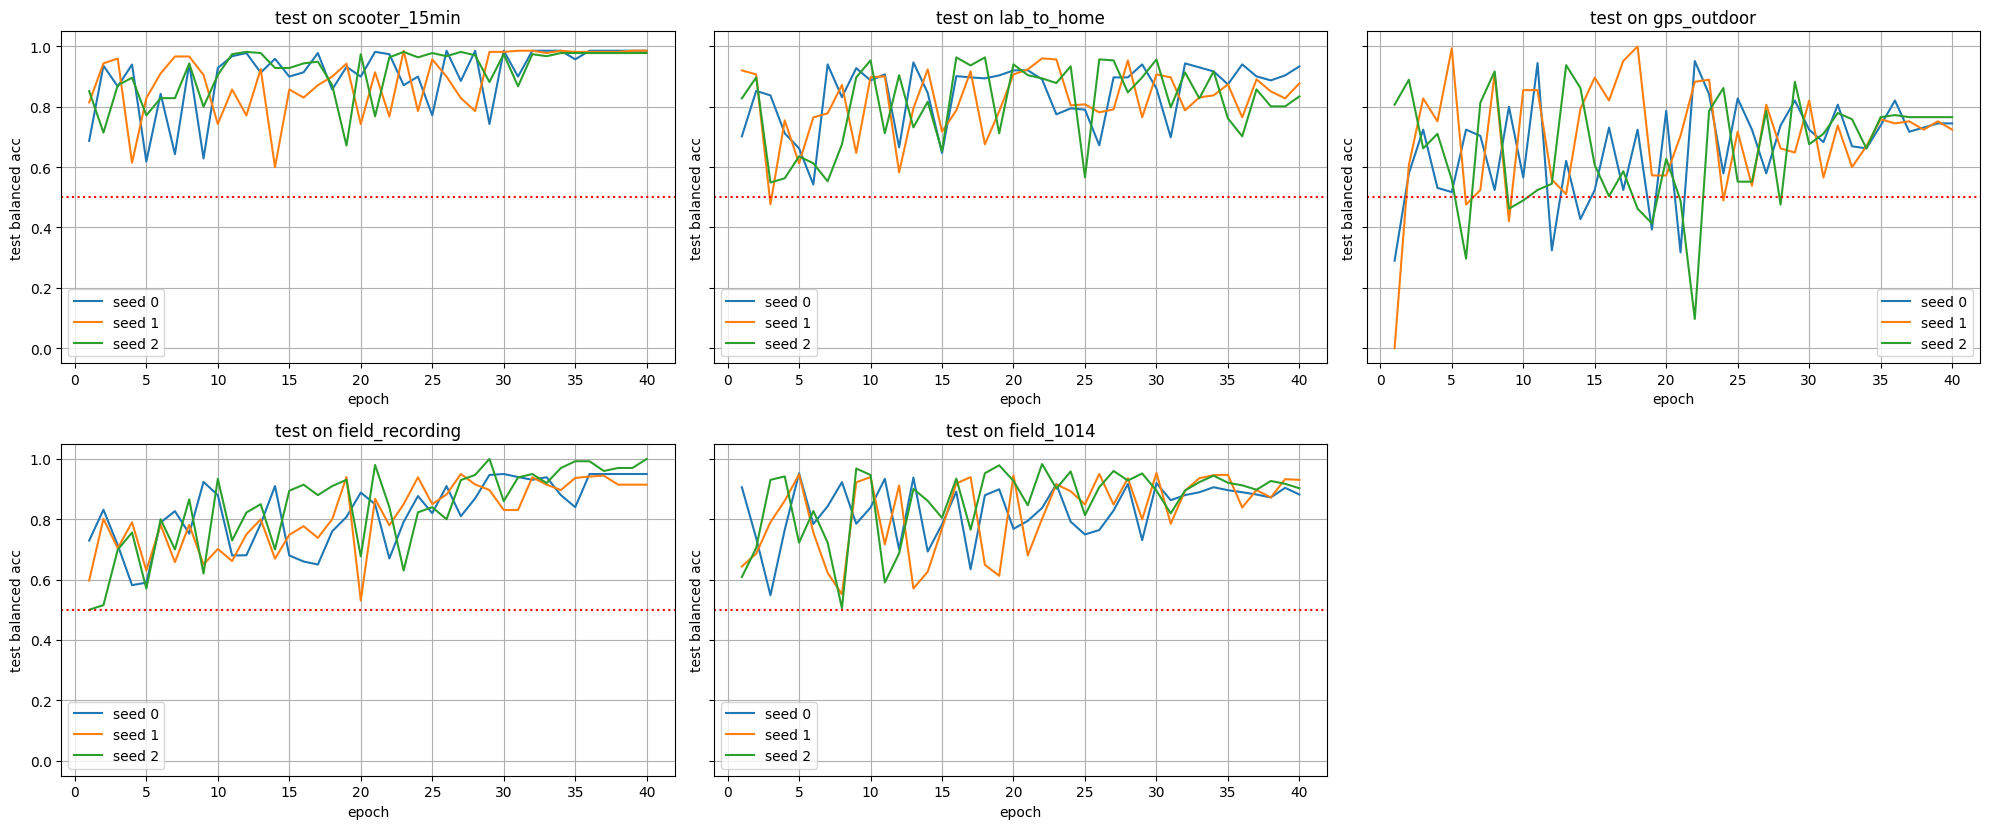

In [12]:
# 11. Leave-one-recording-out: train on the other recordings, test on the unseen one (3 seeds)

import time

ckpt_dir = out_dir / "loro_checkpoints"
ckpt_dir.mkdir(exist_ok = True)

def smooth_probs(meta, probs, n = 3):
    order = np.argsort(meta["t_start"].to_numpy())
    t = meta["t_start"].to_numpy()[order]
    segment = np.concatenate([[0], np.cumsum(np.diff(t) > step_s + 0.1)])
    p = pd.Series(probs[order, 1])
    p_smooth = p.groupby(segment).transform(lambda s: s.rolling(n, center = True, min_periods = 1).mean()).to_numpy()
    out = np.empty_like(p_smooth)
    out[order] = p_smooth
    return out

def recalls(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels = [0, 1])
    return cm.diagonal() / np.maximum(cm.sum(axis = 1), 1)

results = []
histories = {}
loro_parts = []
for test_rec in test_recs:
    ck = ckpt_dir / f"{test_rec}.pkl"
    if ck.exists():
        saved = pd.read_pickle(ck)
        results.append(saved["result"])
        loro_parts.append(saved["part"])
        histories.update(saved["histories"])
        print(f"loaded from checkpoint: test_on = {test_rec}")
        continue

    t_start = time.time()
    test_idx = np.where(win_meta["recording"] == test_rec)[0]
    train_idx = np.where(win_meta["recording"] != test_rec)[0]
    y_test = y_all[test_idx]

    seed_probs, seed_acc = [], []
    for seed in seeds:
        model, hist, probs = train_model(train_idx, test_idx, seed = seed)
        seed_probs.append(probs)
        seed_acc.append(balanced_accuracy_score(y_test, probs.argmax(axis = 1)))
        histories[(test_rec, seed)] = hist
    ens = np.mean(seed_probs, axis = 0)
    p_asphalt_smooth = smooth_probs(win_meta.iloc[test_idx], ens)

    part = win_meta.iloc[test_idx][["recording", "t_start", "label", "speed_mps", "lat", "lon"]].copy()
    part["p_asphalt"] = ens[:, 1]
    part["pred"] = np.where(ens[:, 1] >= 0.5, "asphalt", "sidewalk")
    loro_parts.append(part)

    pred_raw = ens.argmax(axis = 1)
    pred_smooth = (p_asphalt_smooth >= 0.5).astype(int)
    r_raw, r_smooth = recalls(y_test, pred_raw), recalls(y_test, pred_smooth)
    res = {"test_on": test_rec, "n_sidewalk": int((y_test == 0).sum()), "n_asphalt": int((y_test == 1).sum()),
           "seed_bal_acc_mean": np.mean(seed_acc), "seed_bal_acc_std": np.std(seed_acc),
           "ens_recall_sidewalk": r_raw[0], "ens_recall_asphalt": r_raw[1],
           "smooth_recall_sidewalk": r_smooth[0], "smooth_recall_asphalt": r_smooth[1],
           "smooth_bal_acc": balanced_accuracy_score(y_test, pred_smooth)}
    results.append(res)
    pd.to_pickle({"result": res, "part": part, "histories": {(test_rec, s): histories[(test_rec, s)] for s in seeds}}, ck)
    print(f"done: test_on = {test_rec}  ({(time.time() - t_start) / 60:.1f} min, saved)")

loro = pd.concat(loro_parts, ignore_index = True)
loro["correct"] = loro["pred"] == loro["label"]
loro.to_csv(out_dir / "cnn_loro_predictions.csv", index = False)

results_df = pd.DataFrame(results)
display(results_df.round(3))
results_df.to_csv(out_dir / "cnn_loro_results_12s_accel.csv", index = False)

n_cols = 3
n_rows = math.ceil(len(test_recs) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize = (20, 4.2 * n_rows), sharey = True)
for ax_plot in axes.flat[len(test_recs):]:
    ax_plot.axis("off")
for ax_plot, test_rec in zip(axes.flat, test_recs):
    for seed in seeds:
        hist = histories[(test_rec, seed)]
        ax_plot.plot(hist["epoch"], hist["test_bal_acc"], label = f"seed {seed}")
    ax_plot.axhline(0.5, color = "r", linestyle = ":")
    ax_plot.set_title(f"test on {test_rec}")
    ax_plot.set_xlabel("epoch")
    ax_plot.set_ylabel("test balanced acc")
    ax_plot.grid(True)
    ax_plot.legend()
plt.tight_layout()
plt.savefig(out_dir / "training_curves.png", dpi = 120)
plt.show()

In [13]:
# 12. GPS check: does GPS speed help? accel vs accel + speed vs speed only, on the same windows

import time

def recalls(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels = [0, 1])
    return cm.diagonal() / np.maximum(cm.sum(axis = 1), 1)

settings = ["accel", "accel + speed", "speed only"]
gps_idx = np.where(win_meta["speed_mps"].notna())[0]
gps_rec_arr = win_meta["recording"].to_numpy()[gps_idx]
gps_ckpt_dir = out_dir / "gps_checkpoints"
gps_ckpt_dir.mkdir(exist_ok = True)

gps_parts = []
for test_rec in gps_recs:
    ck = gps_ckpt_dir / f"{test_rec}.pkl"
    if ck.exists():
        gps_parts.append(pd.read_pickle(ck))
        print(f"loaded from checkpoint: test_on = {test_rec}")
        continue
    t_start = time.time()
    test_idx = gps_idx[gps_rec_arr == test_rec]
    train_idx = gps_idx[gps_rec_arr != test_rec]
    part = win_meta.iloc[test_idx][["recording", "t_start", "label", "speed_mps"]].copy()
    part["p_accel"] = np.mean([train_model(train_idx, test_idx, seed = s)[2][:, 1] for s in seeds], axis = 0)
    part["p_accel + speed"] = np.mean([train_model(train_idx, test_idx, seed = s, E = E_speed)[2][:, 1] for s in seeds], axis = 0)
    speed_clf = make_pipeline(StandardScaler(), LogisticRegression(class_weight = "balanced")).fit(E_speed[train_idx], y_all[train_idx])
    part["p_speed only"] = speed_clf.predict_proba(E_speed[test_idx])[:, 1]
    gps_parts.append(part)
    pd.to_pickle(part, ck)
    print(f"done: test_on = {test_rec}  ({(time.time() - t_start) / 60:.1f} min, saved)")

gps_loro = pd.concat(gps_parts, ignore_index = True)
gps_loro.to_csv(out_dir / "gps_comparison_predictions.csv", index = False)

rows = []
for setting in settings:
    pred = np.where(gps_loro[f"p_{setting}"] >= 0.5, "asphalt", "sidewalk")
    for rec in gps_recs + ["ALL (pooled)"]:
        sel = (gps_loro["recording"] == rec).to_numpy() if rec in gps_recs else np.ones(len(gps_loro), bool)
        truth = gps_loro["label"].to_numpy()[sel]
        r = recalls((truth == "asphalt").astype(int), (pred[sel] == "asphalt").astype(int))
        rows.append({"setting": setting, "recording": rec, "n_sidewalk": int((truth == "sidewalk").sum()),
                     "n_asphalt": int((truth == "asphalt").sum()),
                     "recall_sidewalk": r[0] if (truth == "sidewalk").any() else np.nan,
                     "recall_asphalt": r[1] if (truth == "asphalt").any() else np.nan,
                     "accuracy": (pred[sel] == truth).mean()})
gps_results = pd.DataFrame(rows)
gps_results.to_csv(out_dir / "gps_comparison_results.csv", index = False)
display(gps_results.pivot(index = "recording", columns = "setting", values = ["recall_sidewalk", "recall_asphalt"]).round(3))
display(gps_results[gps_results["recording"] == "ALL (pooled)"].round(3))

print("speed by surface (m/s):")
print(win_meta.groupby("label")["speed_mps"].describe()[["count", "25%", "50%", "75%"]].round(2))
print()

loro_path = out_dir / "cnn_loro_predictions.csv"
if "loro" not in globals() and loro_path.exists():
    loro = pd.read_csv(loro_path)
    loro["correct"] = loro["pred"] == loro["label"]
if "loro" in globals():
    speed_bins = [0, 1.5, 3, 4.5, 6, 20]
    by_speed = loro.dropna(subset = ["speed_mps"]).assign(speed_bin = lambda d: pd.cut(d["speed_mps"], speed_bins))
    print("main model (accel only, all-recording LORO) by speed:")
    print(by_speed.groupby(["speed_bin", "label"], observed = True)["correct"].agg(["count", "mean"]).round(3))
else:
    print("main model by speed: skipped, run cell 10 to the end first (it writes cnn_loro_predictions.csv)")

done: test_on = lab_to_home  (0.9 min, saved)
done: test_on = gps_outdoor  (0.5 min, saved)
done: test_on = field_recording  (0.5 min, saved)
done: test_on = field_1014  (0.5 min, saved)


recall_sidewalk                          recall_asphalt  \
setting                   accel accel + speed speed only          accel   
recording                                                                 
ALL (pooled)              0.727         0.698      0.599          0.873   
field_1014                0.925         0.910      0.433          0.931   
field_recording           0.656         0.594      0.156          0.903   
gps_outdoor               0.537         0.507      1.000            NaN   
lab_to_home               1.000         1.000      0.333          0.824   

                                          
setting         accel + speed speed only  
recording                                 
ALL (pooled)            0.865      0.622  
field_1014              0.944      0.556  
field_recording         0.903      0.710  
gps_outdoor               NaN        NaN  
lab_to_home             0.800      0.616

,setting,recording,n_sidewalk,n_asphalt,recall_sidewalk,recall_asphalt,accuracy
4,accel,ALL (pooled),172,259,0.727,0.873,0.814
9,accel + speed,ALL (pooled),172,259,0.698,0.865,0.798
14,speed only,ALL (pooled),172,259,0.599,0.622,0.613


speed by surface (m/s):
          count   25%   50%   75%
label                            
asphalt   270.0  3.84  4.99  6.18
sidewalk  176.0  2.74  3.71  4.78

main model (accel only, all-recording LORO) by speed:
                      count   mean
speed_bin   label                 
(0.0, 1.5]  asphalt       2  0.500
            sidewalk     14  0.714
(1.5, 3.0]  asphalt       6  0.167
            sidewalk     44  0.727
(3.0, 4.5]  asphalt      96  0.781
            sidewalk     58  0.879
(4.5, 6.0]  asphalt      82  0.976
            sidewalk     47  0.894
(6.0, 20.0] asphalt      69  1.000
            sidewalk      7  0.571


In [15]:
# 13. Final model on all labeled windows (acceleration only), saved with its settings

final_idx = np.arange(len(win_meta))
final_states = []
for seed in seeds:
    model, hist, _ = train_model(final_idx, final_idx, seed = seed)
    final_states.append({k: v.cpu() for k, v in model.state_dict().items()})
    print(f"seed {seed}: final train loss = {hist['train_loss'].iloc[-1]:.3f}")

final_mean = X_sig[final_idx].mean(axis = (0, 2))[:, None]
final_std = X_sig[final_idx].std(axis = (0, 2))[:, None]

final_path = out_dir / "surface_cnn_final.pt"
torch.save({"state_dicts": final_states,
            "mean": final_mean, "std": final_std,
            "use_channels": use_channels, "classes": classes,
            "fs": fs, "win_s": win_s, "crop_len": crop_len,
            "band": (0.5, 80), "grav_hz": 0.3, "rms_min": float(np.e),
            "train_recordings": sorted(win_meta["recording"].unique()),
            "n_windows": int(len(final_idx))}, final_path)
print("saved:", final_path)

check = torch.load(final_path, weights_only = False)
reloaded = SurfaceCNN(n_in = len(check["use_channels"])).to(device)
reloaded.load_state_dict(check["state_dicts"][0])
print("reload ok:", sum(p.numel() for p in reloaded.parameters()), "parameters")

seed 0: final train loss = 0.034
seed 1: final train loss = 0.021
seed 2: final train loss = 0.024
saved: /content/drive/MyDrive/scooter_data/classification_full/surface_cnn_final.pt
reload ok: 130722 parameters


SURFACE CLASSIFICATION FROM IMU (leave-one-recording-out, all recordings)
input: ['a_vert', 'a_horiz'], window = 12s, step = 2s, fs = 200 Hz
model: 1D-CNN, ensemble of 3 seeds, 40 epochs, cosine LR, augmentation
recordings: 5 (4 with GPS)
windows: 862  (sidewalk = 349, asphalt = 513)

per recording (model never saw the test recording):


,recording,gps,n_sidewalk,n_asphalt,recall_sidewalk,recall_asphalt,accuracy
0,scooter_15min,False,35,131,0.971,0.992,0.988
1,lab_to_home,True,17,151,1.000,0.788,0.810
2,gps_outdoor,True,145,0,0.738,NaN,0.738
3,field_recording,True,50,65,0.900,1.000,0.957
4,field_1014,True,102,166,0.843,0.970,0.922


pooled over all recordings:
  accuracy          = 0.886
  balanced accuracy = 0.877
  recall sidewalk   = 0.828
  recall asphalt    = 0.926

              precision    recall  f1-score   support

    sidewalk      0.884     0.828     0.855       349
     asphalt      0.888     0.926     0.906       513

    accuracy                          0.886       862
   macro avg      0.886     0.877     0.881       862
weighted avg      0.886     0.886     0.886       862



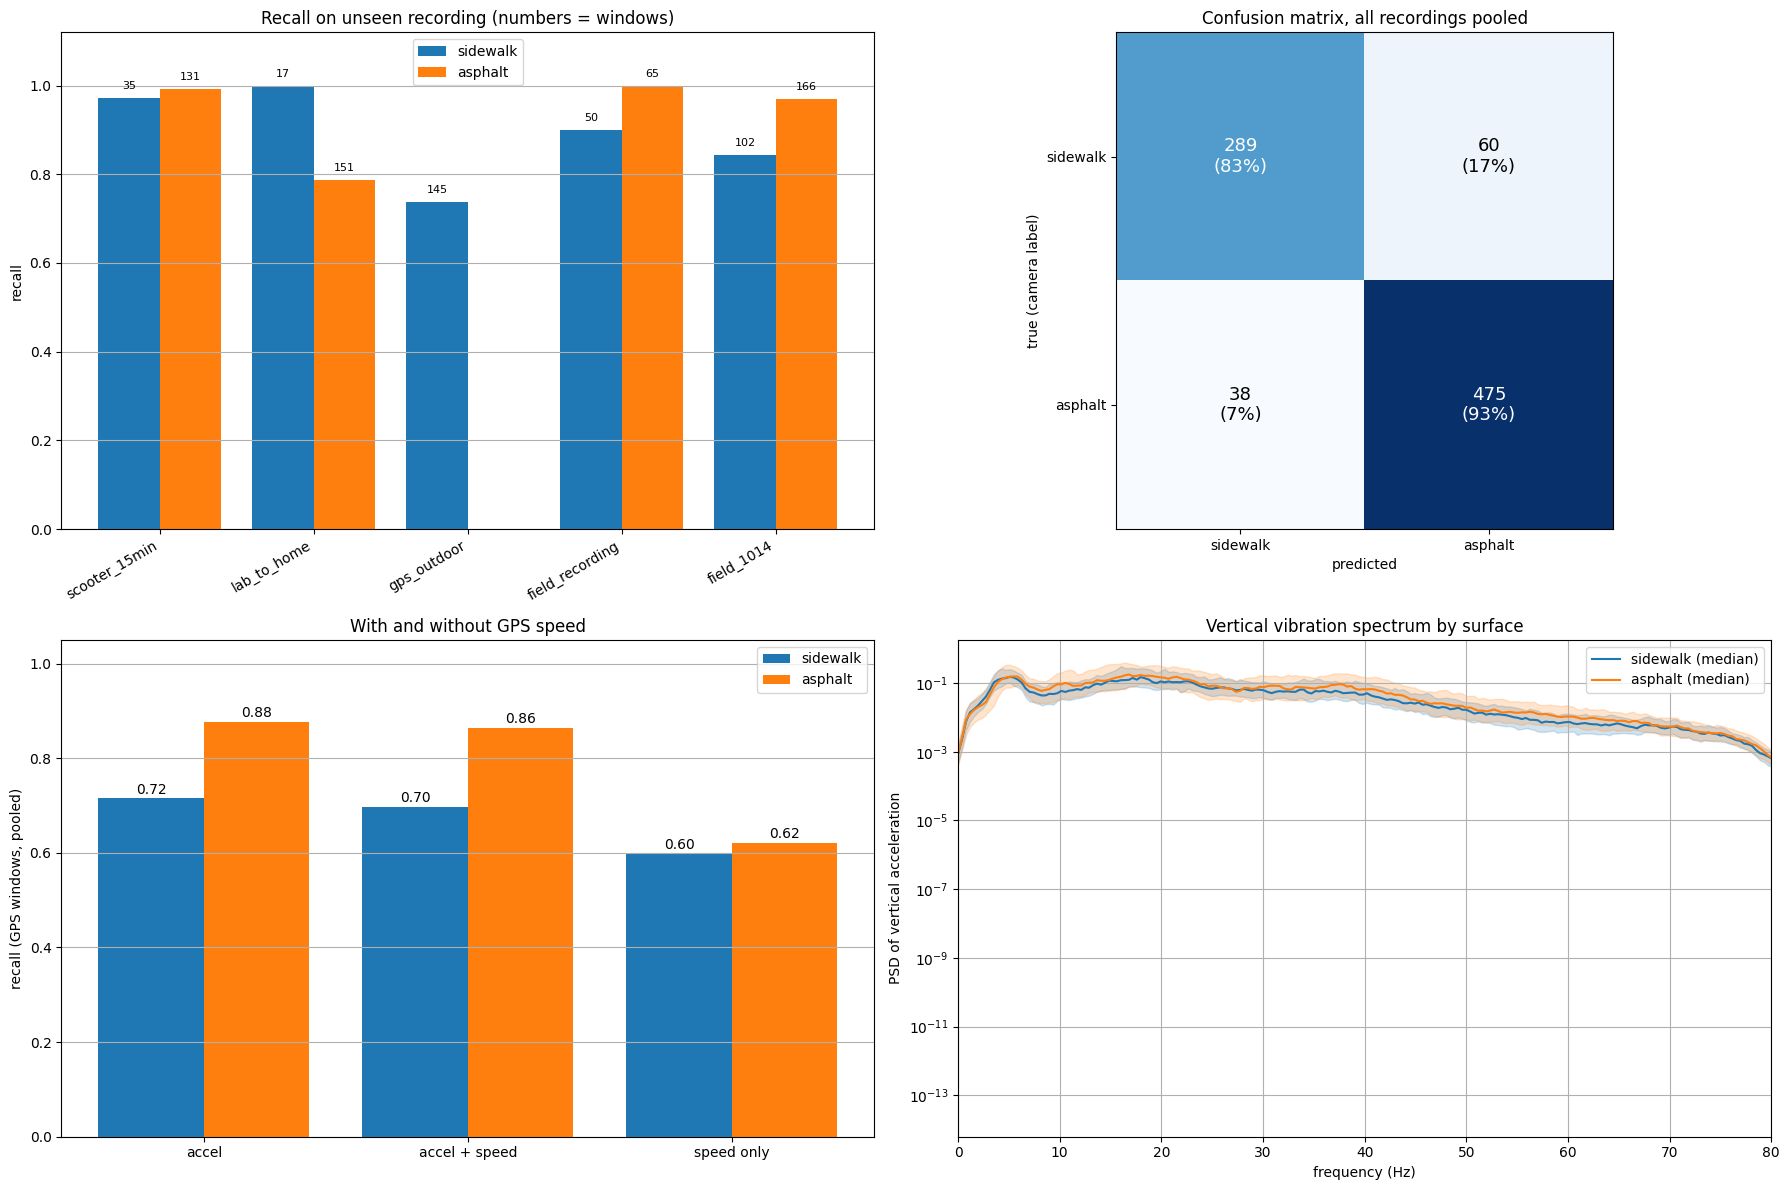

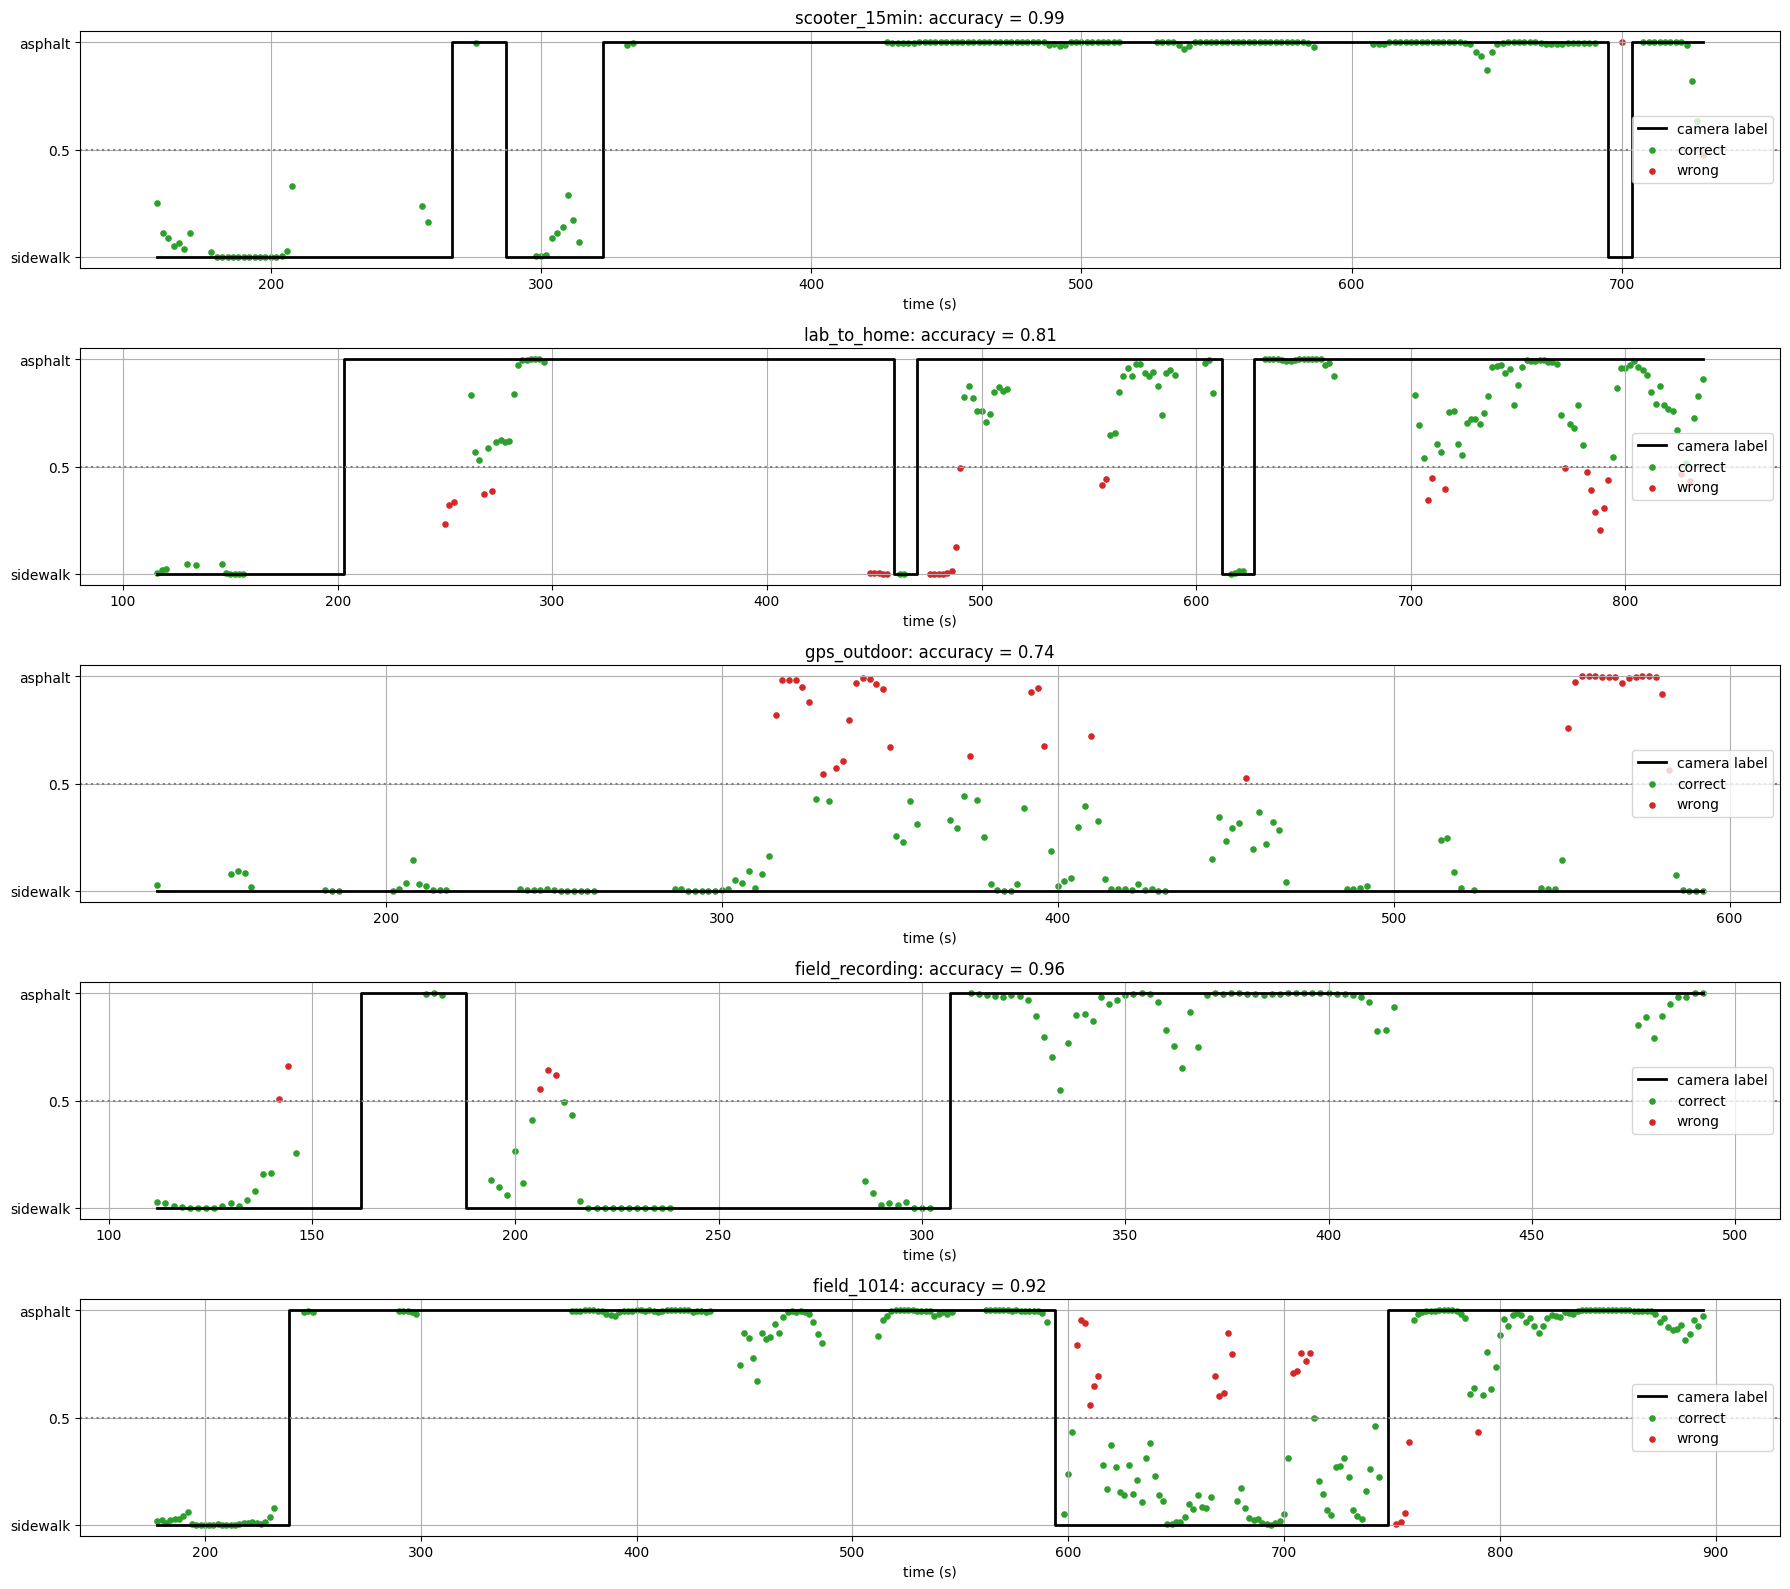

saved: /content/drive/MyDrive/scooter_data/classification_full/results_summary.png | /content/drive/MyDrive/scooter_data/classification_full/results_timelines.png


In [16]:
# 14. Results: per-recording and pooled metrics, confusion matrix, figures

settings = ["accel", "accel + speed", "speed only"]
loro = pd.read_csv(out_dir / "cnn_loro_predictions.csv")
gps_results = pd.read_csv(out_dir / "gps_comparison_results.csv")

per_rec = []
for rec in test_recs:
    g = loro[loro["recording"] == rec]
    sw, asph = g[g["label"] == "sidewalk"], g[g["label"] == "asphalt"]
    per_rec.append({"recording": rec, "gps": rec in gps_recs, "n_sidewalk": len(sw), "n_asphalt": len(asph),
                    "recall_sidewalk": (sw["pred"] == "sidewalk").mean() if len(sw) else np.nan,
                    "recall_asphalt": (asph["pred"] == "asphalt").mean() if len(asph) else np.nan,
                    "accuracy": g["correct"].mean()})
per_rec = pd.DataFrame(per_rec)

cm = confusion_matrix(loro["label"], loro["pred"], labels = classes)
pooled_recall = cm.diagonal() / cm.sum(axis = 1)

print("=" * 70)
print("SURFACE CLASSIFICATION FROM IMU (leave-one-recording-out, all recordings)")
print("=" * 70)
print(f"input: {use_channels}, window = {win_s}s, step = {step_s}s, fs = {fs} Hz")
print(f"model: 1D-CNN, ensemble of {len(seeds)} seeds, 40 epochs, cosine LR, augmentation")
print(f"recordings: {len(test_recs)} ({len(gps_recs)} with GPS)")
print(f"windows: {len(loro)}  (sidewalk = {(loro['label'] == 'sidewalk').sum()}, asphalt = {(loro['label'] == 'asphalt').sum()})")
print()
print("per recording (model never saw the test recording):")
display(per_rec.round(3))
print("pooled over all recordings:")
print(f"  accuracy          = {loro['correct'].mean():.3f}")
print(f"  balanced accuracy = {balanced_accuracy_score(loro['label'], loro['pred']):.3f}")
print(f"  recall sidewalk   = {pooled_recall[0]:.3f}")
print(f"  recall asphalt    = {pooled_recall[1]:.3f}")
print()
print(classification_report(loro["label"], loro["pred"], labels = classes, digits = 3))

fig, axes = plt.subplots(2, 2, figsize = (18, 12))

x = np.arange(len(per_rec))
axes[0, 0].bar(x - 0.2, per_rec["recall_sidewalk"].fillna(0), 0.4, label = "sidewalk")
axes[0, 0].bar(x + 0.2, per_rec["recall_asphalt"].fillna(0), 0.4, label = "asphalt")
for i, row in per_rec.iterrows():
    if row["n_sidewalk"] > 0:
        axes[0, 0].text(i - 0.2, row["recall_sidewalk"] + 0.02, f"{row['n_sidewalk']}", ha = "center", fontsize = 8)
    if row["n_asphalt"] > 0:
        axes[0, 0].text(i + 0.2, row["recall_asphalt"] + 0.02, f"{row['n_asphalt']}", ha = "center", fontsize = 8)
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(per_rec["recording"], rotation = 30, ha = "right")
axes[0, 0].set_ylim(0, 1.12)
axes[0, 0].set_ylabel("recall")
axes[0, 0].set_title("Recall on unseen recording (numbers = windows)")
axes[0, 0].legend()
axes[0, 0].grid(True, axis = "y")

axes[0, 1].imshow(cm, cmap = "Blues")
for i in range(2):
    for j in range(2):
        axes[0, 1].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%})", ha = "center", va = "center",
                        color = "white" if cm[i, j] > cm.max() / 2 else "black", fontsize = 13)
axes[0, 1].set_xticks([0, 1])
axes[0, 1].set_yticks([0, 1])
axes[0, 1].set_xticklabels(classes)
axes[0, 1].set_yticklabels(classes)
axes[0, 1].set_xlabel("predicted")
axes[0, 1].set_ylabel("true (camera label)")
axes[0, 1].set_title("Confusion matrix, all recordings pooled")

pooled = gps_results[gps_results["recording"] == "ALL (pooled)"].set_index("setting").loc[settings]
xa = np.arange(len(settings))
axes[1, 0].bar(xa - 0.2, pooled["recall_sidewalk"], 0.4, label = "sidewalk")
axes[1, 0].bar(xa + 0.2, pooled["recall_asphalt"], 0.4, label = "asphalt")
for i, (rs, ra) in enumerate(zip(pooled["recall_sidewalk"], pooled["recall_asphalt"])):
    axes[1, 0].text(i - 0.2, rs + 0.01, f"{rs:.2f}", ha = "center")
    axes[1, 0].text(i + 0.2, ra + 0.01, f"{ra:.2f}", ha = "center")
axes[1, 0].set_xticks(xa)
axes[1, 0].set_xticklabels(settings)
axes[1, 0].set_ylim(0, 1.05)
axes[1, 0].set_ylabel("recall (GPS windows, pooled)")
axes[1, 0].set_title("With and without GPS speed")
axes[1, 0].legend()
axes[1, 0].grid(True, axis = "y")

for c, color in [("sidewalk", "tab:blue"), ("asphalt", "tab:orange")]:
    sig = X_sig[win_meta["label"].to_numpy() == c, 0, :]
    f, p = welch(sig, fs = fs, nperseg = 512, axis = 1)
    axes[1, 1].semilogy(f, np.median(p, axis = 0), color = color, label = f"{c} (median)")
    axes[1, 1].fill_between(f, np.percentile(p, 25, axis = 0), np.percentile(p, 75, axis = 0), color = color, alpha = 0.2)
axes[1, 1].set_xlim(0, 80)
axes[1, 1].set_xlabel("frequency (Hz)")
axes[1, 1].set_ylabel("PSD of vertical acceleration")
axes[1, 1].set_title("Vertical vibration spectrum by surface")
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig(out_dir / "results_summary.png", dpi = 150)
plt.show()

fig, axes = plt.subplots(len(test_recs), 1, figsize = (18, 3.2 * len(test_recs)))
for ax_plot, rec in zip(np.atleast_1d(axes), test_recs):
    g = loro[loro["recording"] == rec].sort_values("t_start")
    t_mid = g["t_start"] + win_s / 2
    truth = (g["label"] == "asphalt").astype(int)
    ax_plot.step(t_mid, truth, where = "mid", color = "k", linewidth = 2, label = "camera label")
    ax_plot.scatter(t_mid[g["correct"]], g.loc[g["correct"], "p_asphalt"], s = 14, color = "tab:green", label = "correct")
    ax_plot.scatter(t_mid[~g["correct"]], g.loc[~g["correct"], "p_asphalt"], s = 14, color = "tab:red", label = "wrong")
    ax_plot.axhline(0.5, color = "gray", linestyle = ":")
    ax_plot.set_yticks([0, 0.5, 1])
    ax_plot.set_yticklabels(["sidewalk", "0.5", "asphalt"])
    ax_plot.set_title(f"{rec}: accuracy = {g['correct'].mean():.2f}")
    ax_plot.set_xlabel("time (s)")
    ax_plot.grid(True)
    ax_plot.legend(loc = "center right")
plt.tight_layout()
plt.savefig(out_dir / "results_timelines.png", dpi = 120)
plt.show()

print("saved:", out_dir / "results_summary.png", "|", out_dir / "results_timelines.png")

In [17]:
# 15. Map of the routes with the windows on top (GPS only for checking)

colors = {"sidewalk": "#1f77b4", "asphalt": "#ff7f0e"}
route_palette = ["#4c4c4c", "#2ca02c", "#9467bd", "#8c564b", "#e377c2", "#17becf", "#bcbd22", "#7f7f7f", "#d62728"]
win_all = pd.read_csv(out_dir / "imu_windows_meta.csv").dropna(subset = ["lat", "lon"])
gps_win = loro.dropna(subset = ["lat", "lon"])

def gps_segments(lat, lon, t, max_gap = 10):
    segs, cur, prev = [], [], None
    for a, b, tt in zip(lat, lon, t):
        if prev is not None and tt - prev > max_gap:
            if len(cur) > 1:
                segs.append(cur)
            cur = []
        cur.append([a, b])
        prev = tt
    if len(cur) > 1:
        segs.append(cur)
    return segs

routes = {}
for rec, folder in recs.items():
    acc_t = pd.read_csv(data_dir / folder / "accel.csv", usecols = ["bag_time_ns"])["bag_time_ns"]
    t0, span = acc_t.min(), (acc_t.max() - acc_t.min()) / 1e9
    gps = load_gps(folder, t0)
    if gps is None:
        continue
    pos = gps[gps["latitude_deg"].notna() & (gps["latitude_deg"] != 0)].sort_values("time_sec")
    if len(pos) > 1:
        routes[rec] = (pos, span)

all_lat = pd.concat([p["latitude_deg"] for p, _ in routes.values()]) if routes else win_all["lat"]
all_lon = pd.concat([p["longitude_deg"] for p, _ in routes.values()]) if routes else win_all["lon"]
m = folium.Map(location = [all_lat.median(), all_lon.median()], zoom_start = 16, tiles = None)
folium.TileLayer("OpenStreetMap", name = "street map (OpenStreetMap)", max_zoom = 19).add_to(m)
folium.TileLayer(tiles = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}", attr = "Esri", name = "street map (Esri)", max_native_zoom = 18, max_zoom = 19).add_to(m)

for i, (rec, (pos, span)) in enumerate(routes.items()):
    color = route_palette[i % len(route_palette)]
    source = pos["source"].iloc[0]
    fg = folium.FeatureGroup(name = f"route: {rec} ({source} GPS)")
    inside = (pos["time_sec"] >= 0) & (pos["time_sec"] <= span)
    for part, style in [(pos[~inside], {"weight": 2, "opacity": 0.5, "dash_array": "6 6"}),
                        (pos[inside], {"weight": 5, "opacity": 0.8})]:
        for seg in gps_segments(part["latitude_deg"], part["longitude_deg"], part["time_sec"]):
            folium.PolyLine(seg, color = color, tooltip = f"{rec} ({source} GPS)", **style).add_to(fg)
    start = pos[inside].iloc[0] if inside.any() else pos.iloc[0]
    folium.Marker([start["latitude_deg"], start["longitude_deg"]], tooltip = f"start of {rec}",
                  icon = folium.Icon(color = "green", icon = "play")).add_to(fg)
    fg.add_to(m)

def popup_label(r):
    return (f"{r['recording']}  t = {r['t_start']:.0f} s<br>camera: {r['label']}<br>"
            f"speed: {r['speed_mps']:.1f} m/s")

def popup(r):
    return (f"{r['recording']}  t = {r['t_start']:.0f} s<br>camera: {r['label']}<br>"
            f"IMU: {r['pred']} (p asphalt = {r['p_asphalt']:.2f})<br>speed: {r['speed_mps']:.1f} m/s")

fg = folium.FeatureGroup(name = "camera label (all windows)", show = False)
for _, r in win_all.iterrows():
    folium.CircleMarker([r["lat"], r["lon"]], radius = 4, color = colors[r["label"]], fill = True,
                        fill_opacity = 0.8, weight = 0, popup = popup_label(r)).add_to(fg)
fg.add_to(m)
fg = folium.FeatureGroup(name = "IMU prediction (test windows)", show = True)
for _, r in gps_win.iterrows():
    folium.CircleMarker([r["lat"], r["lon"]], radius = 4, color = colors[r["pred"]], fill = True,
                        fill_opacity = 0.8, weight = 0, popup = popup(r)).add_to(fg)
fg.add_to(m)
fg = folium.FeatureGroup(name = "IMU wrong", show = False)
for _, r in gps_win[~gps_win["correct"]].iterrows():
    folium.CircleMarker([r["lat"], r["lon"]], radius = 5, color = "red", fill = True, fill_opacity = 0.9,
                        weight = 0, popup = popup(r)).add_to(fg)
fg.add_to(m)
folium.LayerControl(collapsed = False).add_to(m)
m.save(str(out_dir / "surface_map.html"))
print("routes on map:", list(routes))
print(f"labeled windows with position: {len(win_all)}   test windows with position: {len(gps_win)} of {len(loro)}")
print("saved:", out_dir / "surface_map.html")
display(m)

routes on map: ['lab_to_home', 'gps_outdoor', 'field_recording', 'field_1014', 'field_1016', 'field_1019', 'field_1020', 'field_1021']
labeled windows with position: 459   test windows with position: 444 of 862
saved: /content/drive/MyDrive/scooter_data/classification_full/surface_map.html


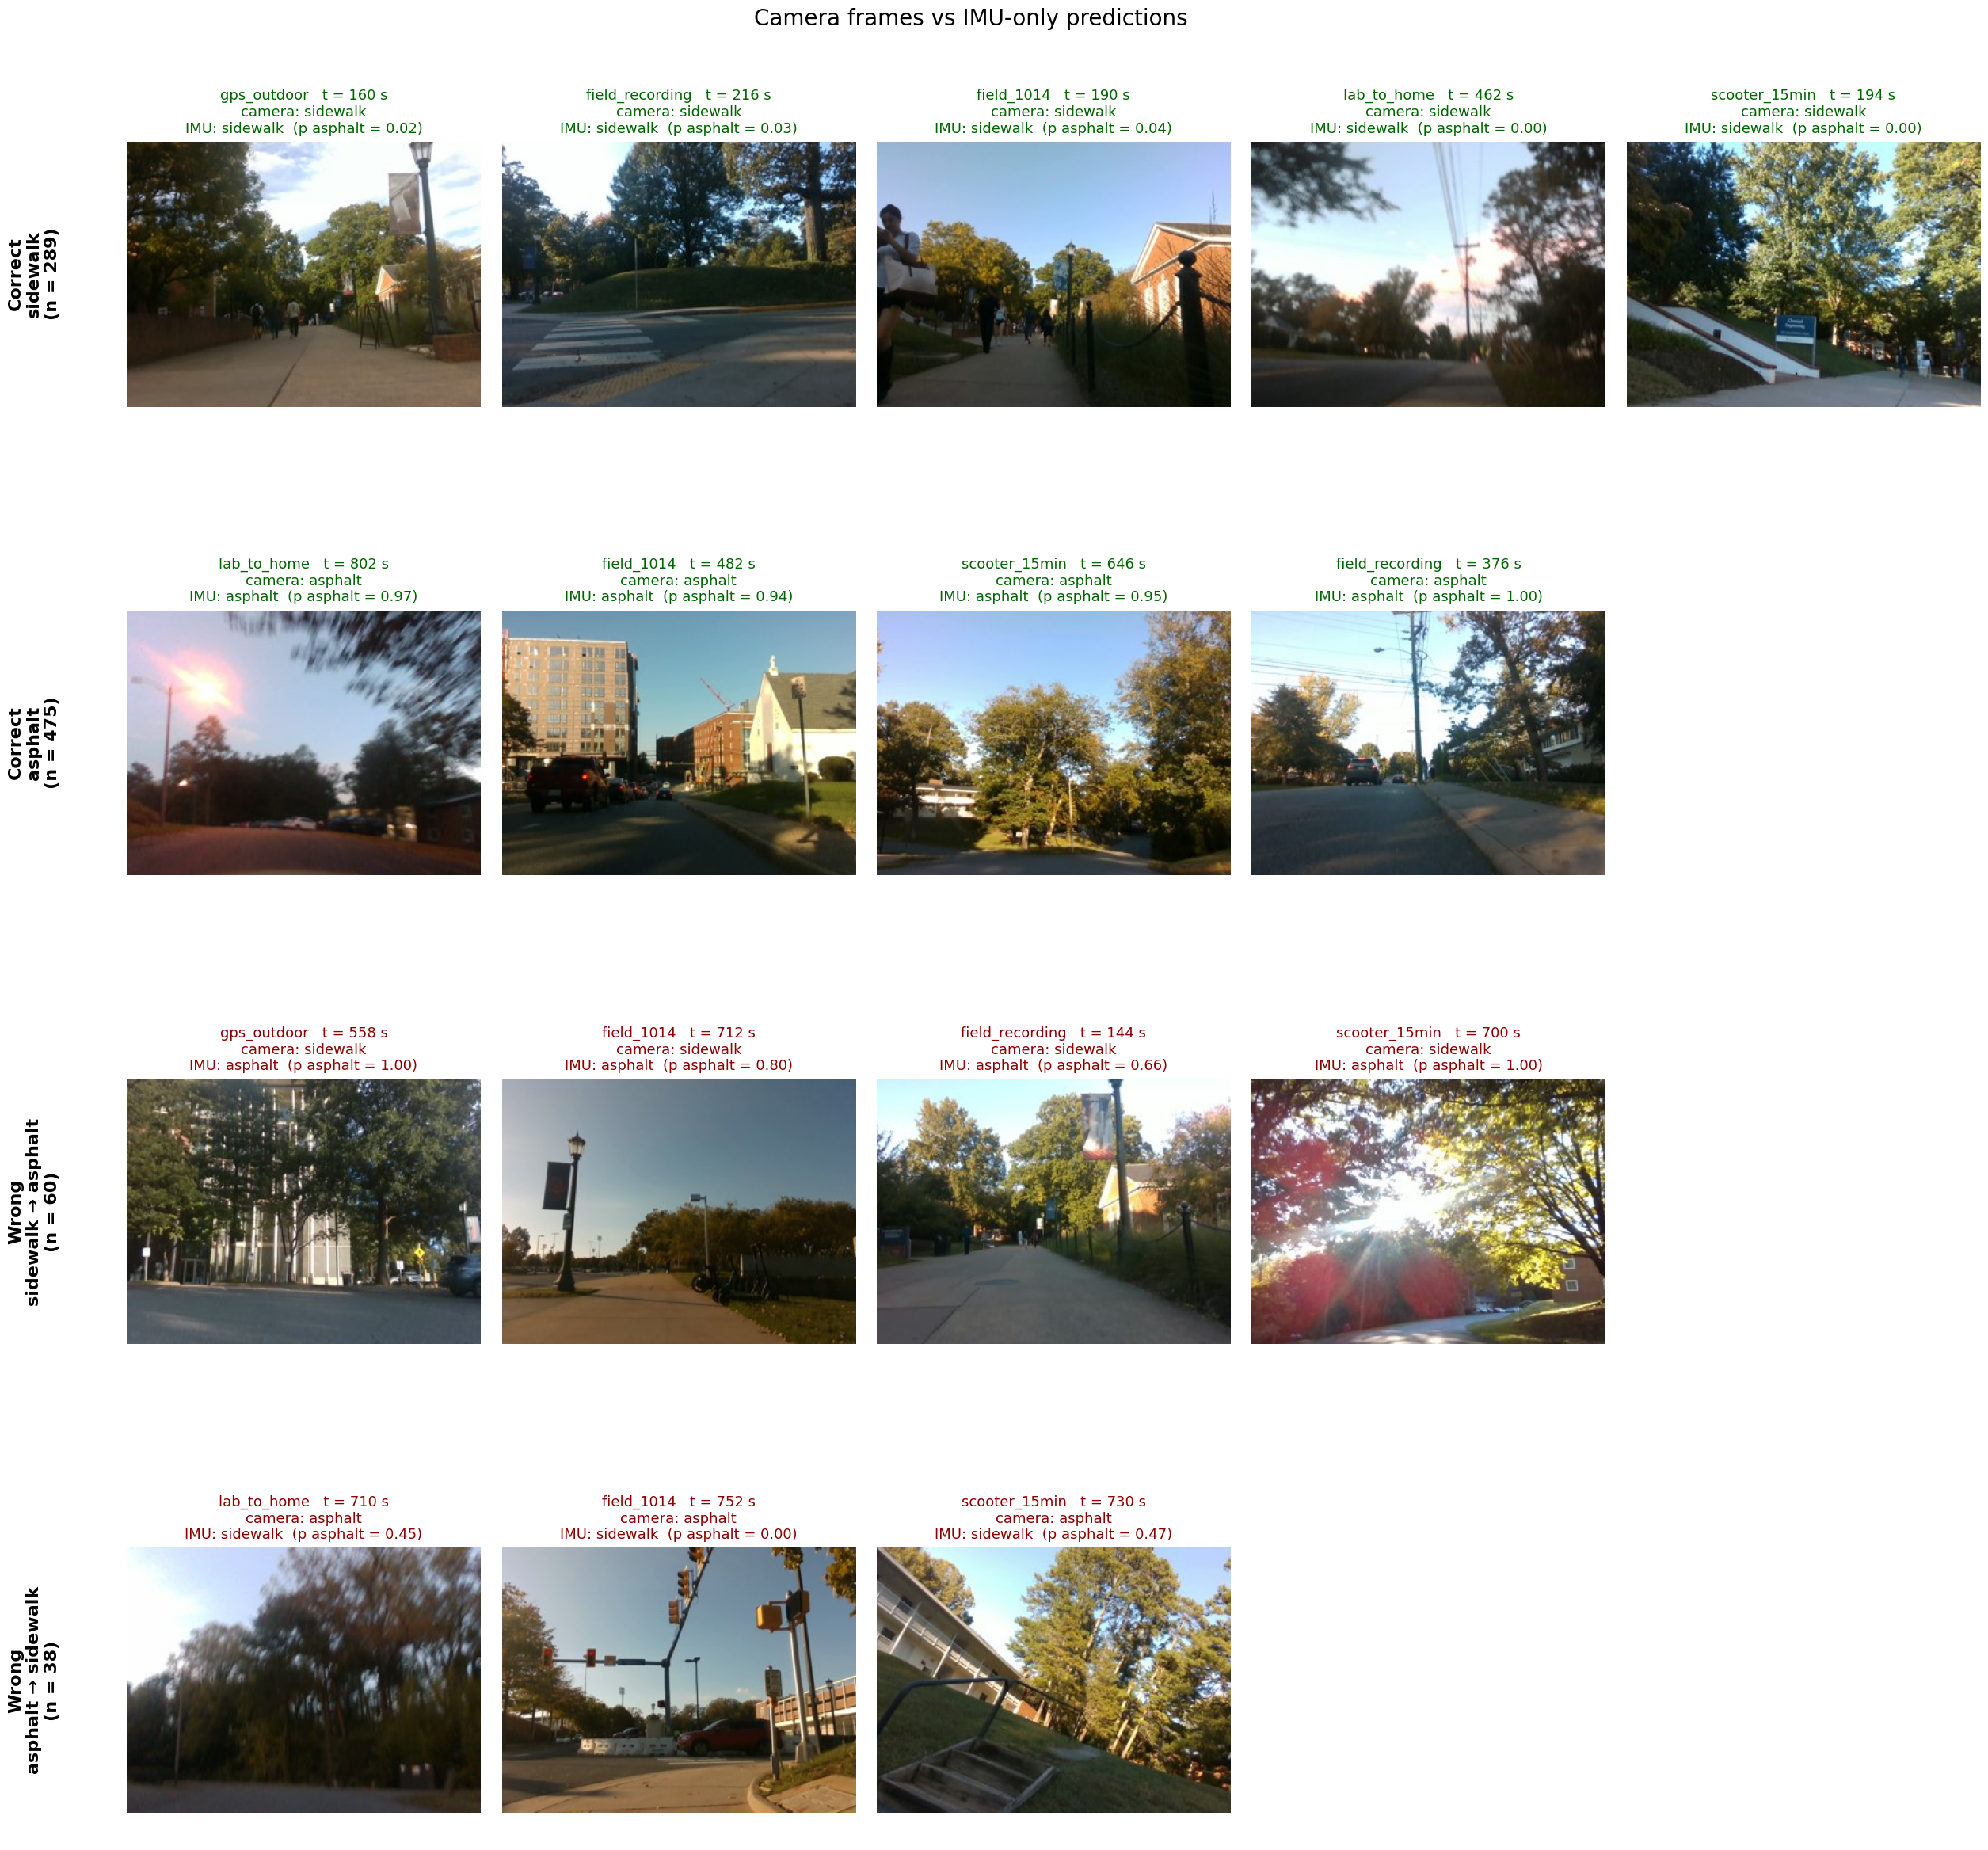

saved: /content/drive/MyDrive/scooter_data/classification_full/results_frames_grid.png


In [18]:
# 16. Camera frames next to IMU predictions: correct and wrong examples

frame_index = pd.concat([pd.read_csv(frames_root / f"{r}_frames.csv") for r in test_recs], ignore_index = True)

def nearest_frame(rec, t):
    f = frame_index[frame_index["recording"] == rec]
    i = (f["t"] - t).abs().idxmin()
    return f.loc[i, "frame"], abs(f.loc[i, "t"] - t)

loro["t_mid"] = loro["t_start"] + win_s / 2
nearest = [nearest_frame(r, t) for r, t in zip(loro["recording"], loro["t_mid"])]
loro["frame"] = [p for p, _ in nearest]
loro["frame_dt"] = [d for _, d in nearest]
shown = loro[loro["frame_dt"] < 1.5]

groups = [("sidewalk", "sidewalk", "Correct\nsidewalk"),
          ("asphalt", "asphalt", "Correct\nasphalt"),
          ("sidewalk", "asphalt", "Wrong\nsidewalk → asphalt"),
          ("asphalt", "sidewalk", "Wrong\nasphalt → sidewalk")]
n_cols = 5

fig, axes = plt.subplots(len(groups), n_cols, figsize = (26, 6 * len(groups)))
fig.subplots_adjust(left = 0.09, right = 0.99, top = 0.93, bottom = 0.02, hspace = 0.45, wspace = 0.06)

for row, (true_c, pred_c, title) in enumerate(groups):
    g = shown[(shown["label"] == true_c) & (shown["pred"] == pred_c)]
    sample = g.sample(frac = 1, random_state = 0).groupby("recording").head(1).head(n_cols)
    for col in range(n_cols):
        ax_plot = axes[row, col]
        ax_plot.axis("off")
        if col < len(sample):
            r = sample.iloc[col]
            ax_plot.imshow(Image.open(r["frame"]))
            color = "darkgreen" if r["label"] == r["pred"] else "darkred"
            ax_plot.set_title(f"{r['recording']}   t = {r['t_mid']:.0f} s\n"
                              f"camera: {r['label']}\n"
                              f"IMU: {r['pred']}  (p asphalt = {r['p_asphalt']:.2f})",
                              fontsize = 13, color = color, pad = 8)
    pos = axes[row, 0].get_position()
    fig.text(0.045, (pos.y0 + pos.y1) / 2, f"{title}\n(n = {len(g)})", rotation = 90,
             ha = "center", va = "center", fontsize = 16, fontweight = "bold")

fig.suptitle("Camera frames vs IMU-only predictions", fontsize = 20, y = 0.985)
plt.savefig(out_dir / "results_frames_grid.png", dpi = 120, bbox_inches = "tight")
plt.show()
print("saved:", out_dir / "results_frames_grid.png")

In [19]:
# 17. Check against the hand-labeled frames only

manual_path = out_dir / "manual_labels.csv"
manual = pd.read_csv(manual_path)
manual = manual[manual["manual"].isin(classes)]

rows = []
for _, mrow in manual.iterrows():
    w = loro[(loro["recording"] == mrow["recording"]) & (loro["t_start"] <= mrow["t"]) & (loro["t_start"] + win_s > mrow["t"])]
    if len(w) == 0:
        continue
    p = w["p_asphalt"].mean()
    rows.append({"recording": mrow["recording"], "t": mrow["t"], "human": mrow["manual"],
                 "p_asphalt": p, "imu": "asphalt" if p >= 0.5 else "sidewalk"})
gold = pd.DataFrame(rows)
gold["correct"] = gold["human"] == gold["imu"]

print(f"hand-labeled frames: {len(manual)},  inside a riding window: {len(gold)}")
print()
cm_gold = confusion_matrix(gold["human"], gold["imu"], labels = classes)
print("IMU prediction vs YOUR labels (rows = your label, cols = IMU) [sidewalk, asphalt]:")
print(cm_gold)
print()
print(f"accuracy          = {gold['correct'].mean():.3f}")
print(f"balanced accuracy = {balanced_accuracy_score(gold['human'], gold['imu']):.3f}")
print(f"recall sidewalk   = {cm_gold[0, 0] / cm_gold[0].sum():.3f}  (n = {cm_gold[0].sum()})")
print(f"recall asphalt    = {cm_gold[1, 1] / cm_gold[1].sum():.3f}  (n = {cm_gold[1].sum()})")
print()
print(gold.groupby("recording")["correct"].agg(["count", "mean"]).round(3))
gold.to_csv(out_dir / "imu_vs_manual_labels.csv", index = False)

hand-labeled frames: 318,  inside a riding window: 162

IMU prediction vs YOUR labels (rows = your label, cols = IMU) [sidewalk, asphalt]:
[[66  8]
 [ 1 87]]

accuracy          = 0.944
balanced accuracy = 0.940
recall sidewalk   = 0.892  (n = 74)
recall asphalt    = 0.989  (n = 88)

                 count   mean
recording                    
field_1014          35  0.971
field_recording     33  0.970
gps_outdoor         34  0.853
lab_to_home         29  1.000
scooter_15min       31  0.935
